# Imports and Constants

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Utils
import numpy as np
import matplotlib.pyplot as plt
import itertools
import random
import os
import json
import scipy
import scipy.stats
import csv

# Signals
from math import sqrt, atan2, log
from sklearn.preprocessing import normalize
from scipy import signal

# For iteration bars
from tqdm.auto import tqdm

# PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision.models import resnet18
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import f1_score, accuracy_score, precision_score, recall_score, confusion_matrix

In [ ]:
# Set the seed for the randoms
def set_random_seed():
    SEED = 104
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    torch.backends.cudnn.deterministic = True
set_random_seed()


ROOT = "./drive/MyDrive/Magistrale/Tesi/"
DATASETS_PATH = ROOT + "Dataset/"
DEV_PATH = DATASETS_PATH + "dev/"
TRAIN_PATH = DATASETS_PATH + "train/"
TEST_PATH = DATASETS_PATH + "test/"

CHECKPOINTS_PATH = ROOT + "ckp/"

# Patience
LEN_STACK_PATIENCE = 4
PATIENCE = 5

# Hparams
LEARNING_RATE = 0.0001
RESNET_LEARNING_RATE = 0.0001
WEIGHT_DECAY = 0.0001
RESNET_WEIGHT_DECAY = 0.0001
EPOCHS = 100
DROPOUT = 0.2
BATCH_SIZE = 64
EMBEDDING_DIM = 128

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", DEVICE)

LABEL = ["acrylic", "aluminium", "brass", "copper", "empty", "lignum_vitae", "nylon", "oak", "pine", "pp", "pvc", "rose_wood", "steel"]
ID_TO_LABEL = {0:"acrylic", 1:"aluminium", 2:"brass", 3:"copper", 4:"empty", 5:"lignum_vitae", 6:"nylon", 7:"oak", 8:"pine", 9:"pp", 10:"pvc", 11:"rose_wood", 12:"steel"}
LABEL_TO_ID = {
    "acrylic": 0,
    "aluminium": 1,
    "brass": 2,
    "copper": 3,
    "empty": 4,
    "lignum_vitae": 5,
    "nylon": 6,
    "oak": 7,
    "pine": 8,
    "pp": 9,
    "pvc": 10,
    "rose_wood": 11,
    "steel": 12
}

device: cuda


# Functions and Dataset

In [ ]:
def find_indices(list_to_check, item_to_find):
    """
    This function allow to find an element in a list.
    Args:
        list_to_check: input array
        item_to_find: the object in the array we want to find
    Return:
        indices: the index of the item
    """
    indices = []
    for idx, value in enumerate(list_to_check):
        if value == item_to_find:
            indices.append(idx)
    return indices

def calculate_median(arr):
    """
    This function allow to calculate the median of each of the array contained in the input array.
    Args:
        arr: the array of arrays whose median we want to compute
    Return:
        medians: the array with all the medians
    """
    medians = []
    for elem in arr:
        medians.append(np.median(elem))
    return np.asarray(medians)

def phase_sanification(csi_phases):
    """
    This function performs the phase calibration.
    Args:
        csi_phases:  the array with all phases collected
    Return:
        all_phase_san: the array with the sanitized amplitude values
    """
    all_phase_san = []
    for phases in csi_phases:
        phases_san = []
        for i, phase in enumerate(phases, start=1):
            b = (1/i) * sum(phases[:i]) # phase

            # if i = 1 the sanification is done by subtracting from the original
            # phase only the calculated phase value since the slope needs the
            # previous value to be calculated
            if i == 1:
                phase_san = phase - b
                phases_san.append(phase_san)
            else:
                a = (phase - phases[0]) / (i - 1) # slope
                phase_san = phase - a*i - b
                phases_san.append(phase_san)
        all_phase_san.append(phases_san)

    all_phase_san = np.asarray(all_phase_san)
    return all_phase_san

def STFT(signal, fs=1, stride=1, wind_wid=5, dft_wid=5, window_type='gaussian'):
    """
    This function performs the computation of the Short Time Fourier Transform (STFT).
    Args:
        signal: Time series of measurement values
        fs: Sampling frequency of the x time series.
        stride: stride of the window.
        wind_wid: the width of the window
        dft_wid: This parameter defines the size of the Discrete Fourier Transform (DFT)
        window_type: the type of window used
    Return:
        f_bins: Array of sample frequencies
        stft_spectrum: STFT of the input signal
    """
    assert dft_wid >= wind_wid and wind_wid > 0 and stride <= wind_wid and stride > 0\
        and isinstance(stride, int) and isinstance(wind_wid, int) and isinstance(dft_wid, int)\
        and isinstance(fs, int) and fs > 0

    if window_type == 'gaussian':
        window = scipy.signal.windows.gaussian(wind_wid, (wind_wid-1)/sqrt(8*log(200)), sym=True)
    elif window_type == 'rect':
        window = np.ones((wind_wid,))
    else:
        window = scipy.signal.get_window(window_type, wind_wid)

    f_bins, t_bins, stft_spectrum = scipy.signal.stft(x=signal, fs=fs, window=window, nperseg=wind_wid, noverlap=wind_wid-stride, nfft=dft_wid,\
        axis=-1, detrend=False, return_onesided=False, boundary='zeros', padded=True)

    # Take the absolute value of the STFT spectrum to get magnitude
    stft_spectrum = np.abs(stft_spectrum)

    # Reshape the spectrum to collapse the second dimension
    stft_spectrum = stft_spectrum.reshape(1068, -1)
    return f_bins, stft_spectrum

def normalize_data(data_1):
    """
    This function performs the normalization of the input data.
    Args:
        data_1: the array with the data to be normalized
    Return:
        data_1_norm: the array with the normalized data
    """
    data_1_abs = abs(data_1)
    data_1_max = data_1_abs.max(axis=0, keepdims=True)  # [121, T] => [1, T]
    data_1_max_rep = np.tile(data_1_max, (data_1_abs.shape[0], 1))  # [1, T] => [121, T]
    data_1_norm = data_1 / data_1_max_rep
    return data_1_norm

def csi_to_spec(csis, W = 91, samplings = 1068, resampling_ratio = 15):
    """
    This function allows the spectrogram computation and sanification.
    In this case, frequencies ranging from -60 to 60 hz are cropped.
    Args:
        csis: the array with all CSI values collected
        W: the length of the Hann window
        samplings: the number of time istants
        resampling_ratio: the resampling ratio
    Return:
        ret: Spectrogram extracted from the CSI data
    """

    _, spec = STFT(csis, fs=resampling_ratio, stride=1, wind_wid=W, dft_wid=samplings, window_type='hann') # [6,1000,T]j
    # Crop
    spec_crop = np.concatenate((spec[:,:61], spec[:,-60:]), axis=1) # [1,1000,T]j=>[1,121,T]j
    # Unwrap
    spec_crop_unwrap = np.roll(spec_crop, shift=60, axis=1) # [1,121,T]j
    # Normalize
    spec_crop_unwrap_norm = normalize_data(spec_crop_unwrap) # [6,121,T] complex
    if np.sum(np.isnan(spec_crop_unwrap_norm)):
        print('>>>>>>>>> NaN detected!')
    ret = spec_crop_unwrap_norm
    return ret

def sanified_spectrogram_alt(csis, hann_window = 91, samplings = 1068, resampling_ratio = 15):
    """
    This function allows the spectrogram computation and sanification.
    The spectrogram is modified in size so that it can be processed by the ResNet network.
    Args:
        csis: the array with all CSI values collected
        hann_window: the length of the Hann window
        samplings: the number of time istants
        resampling_ratio: the resampling ratio
    Return:
        spectrogram_resnet: the spectrogram ready to be processed by ResNet
    """
    csis = csis.squeeze()
    fft_csi = csi_to_spec(csis, W = hann_window, samplings = samplings, resampling_ratio = resampling_ratio)
    spectrogram_resnet = torch.tensor(fft_csi, dtype=torch.float32, device=DEVICE)

    spectrogram_resnet = spectrogram_resnet.permute(1, 0)
    spectrogram_resnet = spectrogram_resnet.unsqueeze(0)
    spectrogram_resnet = spectrogram_resnet.repeat(3, 1, 1)
    spectrogram_resnet = spectrogram_resnet.unsqueeze(0)
    spectrogram_resnet = F.interpolate(spectrogram_resnet, size=(224, 224))
    spectrogram_resnet = spectrogram_resnet.squeeze()
    return spectrogram_resnet

def amplitude_sanification(csi_amplitudes, eps = 3):
    """
    This function allows the sanitization of the amplitude. A range is defined,
    and all values that are outside this range must be replaced with the last
    value within that range. For example, if the range is [-2, 2] and the i-th
    element has value 3 while the i-1-th element has value 1.5 then the i-th
    value must be replaced with the value of i-1 i.e. 1.5.
    Args:
        csi_amplitudes: the array with all amplitudes collected
        eps: eps is an application-dependent constant. Is used to identify the outliers
    Return:
        normalized_amplitude: the array with the sanitized amplitude values
    """
    # median and median absolute deviation calculation
    median = calculate_median(csi_amplitudes)
    mad = scipy.stats.median_abs_deviation(csi_amplitudes, 1)

    thd_m = median - eps*mad
    thd_p = median + eps*mad
    all_amplitudes = []
    prev_val = -1e-8
    for i, amps in enumerate(csi_amplitudes):
        amplitudes = []
        for amp in amps:
            if amp >= thd_m[i] and amp <= thd_p[i]:
                amplitudes.append(amp)
                prev_val = amp
            else:
                amplitudes.append(prev_val)
        # If the first value of the array is not inside the range the value
        # must be replaced with the last value in the range of the array
        if -1e-8 in amplitudes:
            idxs = find_indices(amplitudes, -1e-8)
            if len(idxs) > 1:
                for idx in idxs:
                    amplitudes[int(idx)] = prev_val
            else:
                amplitudes[idxs[0]] = prev_val
        amplitudes = np.asarray(amplitudes)
        all_amplitudes.append(amplitudes)
    all_amplitudes = np.asarray(all_amplitudes)
    # Normalize the array
    normalized_amplitude = normalize(all_amplitudes)
    return normalized_amplitude


In [ ]:
class MyDataset(Dataset):
    def __init__(self, mode, type_box):
        """
        Args:
            mode: "train": if I want use the training set
                  "dev":   if I want use the development set
                  "test":  if I want use the test set
            type_box: "box", "not_box" or "all".
        """
        self.mode = mode
        self.box = type_box
        self.inputs = self.encode()

    def encode(self):
        """
        Method used to construct the array containing the model inputs
        Return:
            input_data: list of the inputs of the model, one dict per CSI packet:
                        {
                            amplitudes, phases, ap, ar, pr, apr: sanified features
                                (and their combinations with the RSSI),
                            rssi: RSSI value of the packet,
                            spectrogram: spectrogram ready for the ResNet,
                            label: class associated to the input
                        }
        """
        dirs = os.listdir(DATASETS_PATH + self.mode)
        input_data = []
        for material in tqdm(dirs, desc = "Material", leave = False):
            for box in os.listdir(DATASETS_PATH + self.mode + "/" + material):
                if self.box == 'box':
                    if box == "without":
                        continue
                elif self.box == 'not_box':
                    if box == "with":
                        continue
                for test in tqdm(os.listdir(DATASETS_PATH + self.mode + "/" + material + '/'+ box), desc = "File", leave = False):
                    with open(DATASETS_PATH + self.mode + "/" + material + '/' + box + "/" + test) as csvfile:
                        csv_reader = csv.reader(csvfile)
                        all_amp = []
                        all_pha = []
                        all_rssi = []
                        fin_rssi = []
                        all_csi = []
                        count = 0
                        for j,row in enumerate(csv_reader):
                            imaginary = []
                            real = []
                            amplitudes = []
                            phases = []
                            rssis = []
                            csis = []

                            # Avoiding elements with errors in dataset
                            if self.box == "box" or (self.box == "all" and box == "with"):
                                if material == "acrylic" and test == "test2.csv":
                                    if j in [703, 842, 850, 863, 864, 983]:
                                        continue
                                elif material == "acrylic" and test == "test4.csv":
                                    if j in [1677, 1693, 1697, 1715, 2567]:
                                        continue
                                elif material == "nylon" and test == "test1.csv":
                                    if j == 6400:
                                        continue
                                elif material == "nylon" and test == "test2.csv":
                                    if j == 5031:
                                        continue
                                elif material == "nylon" and test == "test3.csv":
                                    if j == 3301:
                                        continue
                                elif material == "nylon" and test == "test6.csv":
                                    if j == 6400:
                                        continue
                                elif material == "nylon" and test == "test7.csv":
                                    if j == 5031:
                                        continue
                                elif material == "nylon" and test == "test8.csv":
                                    if j == 3301:
                                        continue
                                elif material == "steel" and test == "test4.csv":
                                    if j == 2167:
                                        continue
                                elif material == "steel" and test == "test5.csv":
                                    if j == 6007:
                                        continue
                                elif material == "steel" and test == "test9.csv":
                                    if j == 2167:
                                        continue
                                elif material == "steel" and test == "test10.csv":
                                    if j == 6007:
                                        continue
                                elif material == "rose_wood" and test == "test5.csv":
                                    if j == 1665:
                                        continue
                                elif material == "rose_wood" and test == "test10.csv":
                                    if j == 1665:
                                        continue
                            if self.box == "not_box" or (self.box == "all" and box == "without"):
                                if material == "copper" and test == "test7.csv":
                                    if j == 1975:
                                        continue
                                if material == "acrylic" and test == "test6.csv":
                                    if j == 2949:
                                        continue
                                if material == "acrylic" and test == "test7.csv":
                                    if j == 2924:
                                        continue
                            csi_column = row[-2][1:-1]
                            rssi_val = int(row[3])
                            csi_raw = [int(x) for x in csi_column.split(" ") if x != '']

                            # Taking the first 1068 time istants, used in the spectrogram calculation,
                            if count < 1068:
                                csis.append(csi_raw)
                                count += 1

                            # Create list of imaginary and real numbers from CSI
                            for i in range(len(csi_raw)):
                                if i % 2 == 0:
                                    imaginary.append(csi_raw[i])
                                else:
                                    real.append(csi_raw[i])

                            # Transform imaginary and real into amplitude and phase
                            for i in range(int(len(csi_raw) / 2)):
                                amplitudes.append(sqrt(imaginary[i] ** 2 + real[i] ** 2))
                                phases.append(atan2(imaginary[i], real[i]))
                                rssis.append(rssi_val)
                            all_amp.append(amplitudes)
                            all_pha.append(phases)
                            all_rssi.append(rssis)
                            fin_rssi.append(rssi_val)
                            if len(csis) != 0:
                                all_csi.append(csis)
                        amplitudes = np.array(all_amp)
                        phases = np.array(all_pha)
                        rssis = np.array(all_rssi)
                        frssi = np.array(fin_rssi)
                        csis = np.array(all_csi)

                        # Sanification phase
                        phase_sanified = phase_sanification(phases)
                        amplitude_sanified = amplitude_sanification(amplitudes)
                        spectrogram = sanified_spectrogram_alt(csis)

                        # entry creation
                        for x, y, z, w in zip(amplitude_sanified, phase_sanified, rssis, frssi):
                            entry = {}
                            entry["amplitudes"] = torch.tensor(x, dtype=torch.float32, device=DEVICE)
                            entry["phases"] = torch.tensor(y, dtype=torch.float32, device=DEVICE)
                            entry["ap"] = torch.tensor([x, y], dtype=torch.float32, device=DEVICE)
                            entry["ar"] = torch.tensor([x, z], dtype=torch.float32, device=DEVICE)
                            entry["pr"] = torch.tensor([y, z], dtype=torch.float32, device=DEVICE)
                            entry["apr"] = torch.tensor([x, y, z], dtype=torch.float32, device=DEVICE)
                            # print(x, y, z)
                            entry["rssi"] = torch.tensor(w, dtype=torch.float32, device=DEVICE)
                            entry["spectrogram"] = spectrogram
                                # spect_count +=1
                            entry["label"] = torch.tensor(LABEL_TO_ID[material], dtype=torch.int64, device=DEVICE)
                            input_data.append(entry)
                            del entry
        return input_data

    def loss_weights(self):
        """
        Method used to calculate weights, based on class frequency,
        to be used on the loss function as the if might be unbalanced.
        Return:
            weights: weights for the loss function.
        """
        label_freq = {}
        for label in LABEL:
            label_freq[label] = 0
        for value in self.inputs:
            label = ID_TO_LABEL[value["label"].item()]
            label_freq[label] += 1
        freqs = list(label_freq.items())
        freqs = np.array([x[1] for x in freqs])
        freqs = 1/freqs
        freqs = freqs / sum(freqs) * len(freqs)
        weights = torch.Tensor(freqs).to(DEVICE)
        return weights

    def __len__(self):
        '''
        Return:
            - number of element in the dataset
        '''
        return len(self.inputs)

    def __getitem__(self, idx):
        '''
        Return:
            - i-th element of the dataset to iterate on it
        '''
        return self.inputs[idx]

    def __str__(self):
        out = "set type: " + self.mode + "Set"
        # out += "\nmu type used: " + self.mu_type
        out += "\nset length: " + str(len(self))
        return out

def data_loading(dataset, shuffle):
    """
    Function used to create a dataloader and print some usefull information.
    Args:
        dataset: dataset on which you want to build the dataloader
        shuffle: whether or not I should shuffle the dataloader obtained
    Return:
        data_loader: the DataLoader object
    """
    data_loader = DataLoader(dataset, batch_size = BATCH_SIZE, shuffle = shuffle)
    print(dataset)
    print("batch size: " + str(BATCH_SIZE))
    print("number of batches: " + str(len(data_loader)))
    return data_loader

# Model

In [ ]:
class Netw(nn.Module):
    def __init__(self, dropout = DROPOUT, num_classes = len(LABEL)):
        super(Netw, self).__init__()

        # CONV 2D
        self.conv1 = nn.Conv2d(1, 64, kernel_size=1, stride=(1, 1))
        self.conv2 = nn.Conv2d(64, 128, kernel_size=1, stride=(1, 1))
        self.conv3 = nn.Conv2d(128, 256, kernel_size=1, stride=(1, 1))

        # CONV 1D
        self.c1d = nn.Conv1d(1, 64, kernel_size=3, stride=2)
        self.c2d = nn.Conv1d(64, 128, kernel_size=3, stride=2)
        self.c3d = nn.Conv1d(128, 256, kernel_size=3, stride=2)

        # ResNet18
        self.resnet = resnet18(weights=None)
        num_ftrs = self.resnet.fc.in_features
        self.resnet.fc = nn.Linear(num_ftrs, num_classes) # change last layer dimension

        # fully connected layers + dropout + activation function
        self.fc1 = nn.Linear(50944 , 256)
        self.fc2 = nn.Linear(256, 128)
        self.fc3 = nn.Linear(128, num_classes)
        self.fc4 = nn.Linear(num_classes*2, num_classes)

        self.dropout = nn.Dropout(dropout)

        self.leaky_relu = nn.LeakyReLU()

        for param in list(self.resnet.parameters()):
            param.requires_grad = False

    def forward(self, x):
        amplitude = x["amplitudes"].clone().detach().to(torch.float32)
        phase = x["phases"].clone().detach().to(torch.float32)
        apr = x["apr"].clone().detach().to(torch.float32) # amplitude + phase + RSSI
        spectrogram = x["spectrogram"].clone().detach().to(torch.float32)
        label = x["label"].clone().detach().to(torch.int64)
        apr = apr.unsqueeze(1)
        input_tensor1 = apr.permute(0, 1, 3, 2)
        input_tensor2 = phase.unsqueeze(1)

        x1 = self.leaky_relu(self.conv1(input_tensor1))
        x2 = self.leaky_relu(self.c1d(input_tensor2))
        x1 = self.dropout(x1)
        x2 = self.dropout(x2)
        x1 = self.leaky_relu(self.conv2(x1))
        x2 = self.leaky_relu(self.c2d(x2))
        x1 = self.dropout(x1)
        x2 = self.dropout(x2)
        x1 = self.leaky_relu(self.conv3(x1))
        x2 = self.leaky_relu(self.c3d(x2))
        x1 = self.dropout(x1)
        x2 = self.dropout(x2)

        x1 = x1.view(x1.size(0), -1) # flatten for concatenation
        x2 = x2.view(x2.size(0), -1) # flatten for concatenation
        x1 = torch.cat((x1, x2), dim = 1) # concatenation of CNN 1D and CNN 2D outputs

        x1 = x1.view(x1.size(0), -1)

        x1 = self.leaky_relu(self.fc1(x1))
        x1 = self.leaky_relu(self.fc2(x1))
        x1 = self.fc3(x1)

        # ResNet spectrogram
        spectrogram = spectrogram.squeeze().squeeze()
        x3 = self.resnet(spectrogram)
        x = torch.cat((x1, x3), dim=1) # concatenation of the combined CNNs with the output of ResNet
        out = self.fc4(x) # classifier
        # The loss is needed in eval mode too: Trainer.evaluate reads output[1]
        loss = self.compute_loss(x1, label)
        return out, loss

    def compute_loss(self, preds: torch.Tensor, labels: torch.Tensor) -> torch.Tensor:
        """
        Compute the loss of the model.
        Args:
            preds (`torch.Tensor`): The predictions of the model.
            labels (`torch.Tensor`): The labels of the model.
        Returns:
            obj:`torch.Tensor`: The loss of the model.
        """
        return F.cross_entropy(preds, labels, weight = LOSS_WEIGHTS)


# Training

In [ ]:
class Trainer():
    def __init__(self, model, optimizer, chk_name):
        """
        Args:
            model: model to train
            optimizer: optimizer to use
            chk_name: name of the checkpoint
        """
        self.model = model
        self.optimizer = optimizer
        self.chk_name = chk_name

        # List of training losses
        self.train_losses = []

        # List of validation losses
        self.valid_losses = []

    def save_model(self):
        '''
        Method used for save the model.
        '''
        torch.save(self.model.state_dict(),
                            os.path.join(CHECKPOINTS_PATH, "name__" + self.chk_name))

    def load_model(self, model_path, losses_path):
        self.model.load_state_dict(torch.load(model_path, map_location=DEVICE))
        with open(losses_path, 'r') as file_json:
            losses = json.load(file_json)
        self.train_losses = losses["train_loss"]
        self.valid_losses = losses["dev_loss"]

    def train(self, train_dataset, valid_dataset, epochs = 100):
        """
        Train the model.
        Args:
            train_dataset: a Dataset or DatasetLoader instance containing
                           the training instances;
            valid_dataset: a Dataset or DatasetLoader instance used to evaluate
                           learning progress;
            epochs: the number of times to iterate over train_dataset.
        Returns:
            train_losses: list of the training losses over the epochs;
            valid_losses: list of the validation losses over the epochs;
            epoch: number of the last epoch (less than epochs if early stopped).
        """
        # EARLY STOPPING VARIABLES
        # Current patience
        self.patience = 0
        # Temporal window of validation losses
        self.patience_stack = [1000 for _ in range(LEN_STACK_PATIENCE*2)]

        # Number of samples in the training set
        self.n_sample = len(train_dataset)
        # List of training losses

        # Validation loss
        valid_loss = 1000.0
        best_valid_loss = 1000.0

        # Start!
        for epoch in tqdm(range(epochs), desc = "Epochs", leave = False):
        # Start training
            epoch_loss = 0.0
            self.model.train()

            # For each batch
            batch_pbar = tqdm(train_dataset, desc = "Training - Batch", leave = False)
            for batch in batch_pbar:
                self.optimizer.zero_grad()
                output = self.model(batch)

                # Compute gradient
                sample_loss = output[1]
                sample_loss.backward()

                self.optimizer.step()

                epoch_loss += sample_loss.tolist()
                batch_pbar.set_postfix({'validation_loss': valid_loss, 'training_loss': sample_loss.item(), 'patience': self.patience})

            # Training epoch loss
            avg_epoch_loss = epoch_loss / len(train_dataset)
            self.train_losses.append(avg_epoch_loss)
            # Validation loss
            valid_loss = self.evaluate(valid_dataset)
            self.valid_losses.append(valid_loss)

            # Save losses
            losses = {
                "dev_loss": self.valid_losses,
                "train_loss": self.train_losses
            }
            with open(CHECKPOINTS_PATH + "losses__name__" + self.chk_name[:-3] + ".json", 'w') as file_json:
                json.dump(losses, file_json)

            # Save checkpoint if valid_loss is the best one
            if (valid_loss < best_valid_loss):
                best_valid_loss = valid_loss
                self.save_model()

            # Patience check
            patience_counter = 0
            # Count how many times the validation loss is greater than
            # that obtained in the previous LEN_STACK*2 epochs
            for past_val_loss in self.patience_stack:
                if past_val_loss < valid_loss:
                    patience_counter += 1
            # If it is greater than at least LEN_STACK_PATIENCE epochs,
            # then increase the patience
            if (patience_counter >= LEN_STACK_PATIENCE):
                self.patience += 1
            # Otherwise decrease it
            else:
                self.patience -= 1
                if self.patience < 0:
                    self.patience = 0
            # If the patience has reached its limit... early stopping!
            if (self.patience == PATIENCE):
                print()
                print("Early stopping!!")
                break
            self.patience_stack = self.patience_stack[1:] + [valid_loss]

    def evaluate(self, valid_dataset):
        """
        Evaluate the model.
        Args:
            valid_dataset: the dataset to use to evaluate the model.
        Return:
            avg_valid_loss: the average validation loss over valid_dataset.
        """
        valid_loss = 0.0
        # set dropout to 0 and dont compute gradient.
        self.model.eval()
        with torch.no_grad():
            batch_pbar = tqdm(valid_dataset, desc = "Validation - Batch", leave = False)
            for batch in batch_pbar:
                # Make the predictions
                output = self.model(batch)

                # Save the loss
                sample_loss = output[1]
                valid_loss += sample_loss.tolist()
                batch_pbar.set_postfix({'validation_loss': sample_loss.item(), 'patience': self.patience})
        avg_valid_loss = valid_loss / len(valid_dataset)
        return avg_valid_loss

    def test(self, test_dataset):
        """
        Test the model.
        Args:
            test_dataset: the dataset to use to test the model.
        Return:
            f1, accuracy, precision, recall scores and cm is the confusion matrix
        """
        # set dropout to 0 and dont compute gradient.
        self.model.eval()
        y_true = []
        y_pred = []
        with torch.no_grad():
            batch_pbar = tqdm(test_dataset, desc="Test - Batch", leave=False)
            for batch in batch_pbar:
                # Make the predictions
                output = self.model(batch)

                # Append the predictions and true labels for the current batch
                y_true.extend(batch["label"].cpu())
                y_pred.extend(output[0].argmax(dim=1).cpu())

        # Compute the metrics over all the batches
        f1 = f1_score(y_true, y_pred, average="weighted")
        accuracy = accuracy_score(y_true, y_pred)
        precision = precision_score(y_true, y_pred, average="weighted")
        recall = recall_score(y_true, y_pred, average="weighted")
        cm = confusion_matrix(y_true, y_pred, normalize = "true")
        print("f1:", f1)
        print("accuracy:", accuracy)
        print("precision:", precision)
        print("recall:", recall)
        return f1, accuracy, precision, recall, cm

# TESTS

In [ ]:
# box -> samples with shielded environment
# not_box -> samples with not shielded environment
# all -> all samples

# print("Reading Train Set...")
# train_dataset = MyDataset("train", 'not_box')
# train_data_loader = data_loading(train_dataset, True)
# LOSS_WEIGHTS = train_dataset.loss_weights()

# print("\nReading Validation Set...")
# dev_dataset = MyDataset("dev", 'not_box')
# dev_data_loader = data_loading(dev_dataset, False)
# # LOSS_WEIGHTS = dev_dataset.loss_weights()

# print("\nReading Test Set...")
# test_dataset = MyDataset("test", 'not_box')
# test_data_loader = data_loading(test_dataset, False)

# print("Reading Train Set...")
# train_dataset = MyDataset("train", 'box')
# train_data_loader = data_loading(train_dataset, True)
# LOSS_WEIGHTS = train_dataset.loss_weights()

# print("\nReading Validation Set...")
# dev_dataset = MyDataset("dev", 'box')
# dev_data_loader = data_loading(dev_dataset, False)
# # LOSS_WEIGHTS = dev_dataset.loss_weights()

# print("\nReading Test Set...")
# test_dataset = MyDataset("test", 'box')
# test_data_loader = data_loading(test_dataset, False)

print("Reading Train Set...")
train_dataset = MyDataset("train", 'all')
train_data_loader = data_loading(train_dataset, True)
LOSS_WEIGHTS = train_dataset.loss_weights()

print("\nReading Validation Set...")
dev_dataset = MyDataset("dev", 'all')
dev_data_loader = data_loading(dev_dataset, False)

print("\nReading Test Set...")
test_dataset = MyDataset("test", 'all')
test_data_loader = data_loading(test_dataset, False)


Reading Test Set...


Material:   0%|          | 0/13 [00:00<?, ?it/s]

File:   0%|          | 0/1 [00:00<?, ?it/s]

<ipython-input-5-ae3481fa4de0>:143: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:275.)
  entry["ap"] = torch.tensor([x, y], dtype=torch.float32, device=DEVICE)


File:   0%|          | 0/1 [00:00<?, ?it/s]

...

File:   0%|          | 0/1 [00:00<?, ?it/s]

File:   0%|          | 0/1 [00:00<?, ?it/s]

File:   0%|          | 0/1 [00:00<?, ?it/s]

File:   0%|          | 0/1 [00:00<?, ?it/s]

set type: testSet
set length: 36412
batch size: 64
number of batches: 569


In [ ]:
model = Netw(dropout=DROPOUT).to(DEVICE)
groups = [
    {
        "params": model.conv1.parameters(),
        "lr": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": model.conv2.parameters(),
        "lr": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": model.conv3.parameters(),
        "lr": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": model.c1d.parameters(),
        "lr": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": model.c2d.parameters(),
        "lr": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": model.c3d.parameters(),
        "lr": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": model.resnet.parameters(),
        "lr": RESNET_LEARNING_RATE,
        "weight_decay": RESNET_WEIGHT_DECAY,
    },
    {
        "params": model.fc1.parameters(),
        "lr": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": model.fc2.parameters(),
        "lr": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": model.fc3.parameters(),
        "lr": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
    },
    {
        "params": model.fc4.parameters(),
        "lr": LEARNING_RATE,
        "weight_decay": WEIGHT_DECAY,
    },
]

optimizer = torch.optim.Adam(groups)
save_hparams = {
    "lr": LEARNING_RATE,
    "rlr": RESNET_LEARNING_RATE,
    "wd": WEIGHT_DECAY,
    "rwd": RESNET_WEIGHT_DECAY,
    "dropout": DROPOUT,
}
chk_name = str(save_hparams).replace("\n", " ").replace("{", "").replace("}", "").replace("'", "").replace(":", "").replace(",", "_").replace(" ", "__")
chk_name += ".pt"
trainer = Trainer(model, optimizer, chk_name)

/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


In [ ]:
trainer.train(train_data_loader, dev_data_loader, 100)

Hyperparameter tuning

In [ ]:
# Define the hyperparameters grid
hyperparams_grid = {
    "lr": [0.0001, 0.001, 0.01, 0.1],  # learning rate
    "rlr": [0.0001, 0.001, 0.01, 0.1],  # resnet learning rate
    "wd": [0.0001, 0.001, 0.01],  # weight decay
    "rwd": [0.0001, 0.001, 0.01],  # renet weight decay
    "dropout": [0.2, 0.5, 0.8]  # dropout rate
}

best_f1 = 0.0
best_hyperparams = None

# Iterate over all combinations of hyperparameters
for lr, rlr, wd, rwd, dropout in list(itertools.product(*hyperparams_grid.values())):
    # Create the model with current hyperparameters
    model = Netw(dropout = dropout).to(DEVICE)
    groups = [
        {
            "params": model.conv1.parameters(),
            "lr": lr,
            "weight_decay": wd,
        },
        {
            "params": model.conv2.parameters(),
            "lr": lr,
            "weight_decay": wd,
        },
        {
            "params": model.conv3.parameters(),
            "lr": lr,
            "weight_decay": wd,
        },
        {
            "params": model.c1d.parameters(),
            "lr": lr,
            "weight_decay": wd,
        },
        {
            "params": model.c2d.parameters(),
            "lr": lr,
            "weight_decay": wd,
        },
        {
            "params": model.c3d.parameters(),
            "lr": lr,
            "weight_decay": wd,
        },
        {
            "params": model.resnet.parameters(),
            "lr": rlr,
            "weight_decay": rwd,
        },
        {
            "params": model.fc1.parameters(),
            "lr": lr,
            "weight_decay": wd,
        },
        {
            "params": model.fc2.parameters(),
            "lr": lr,
            "weight_decay": wd,
        },
        {
            "params": model.fc3.parameters(),
            "lr": lr,
            "weight_decay": wd,
        },
        {
            "params": model.fc4.parameters(),
            "lr": lr,
            "weight_decay": wd,
        },
    ]
    optimizer = torch.optim.Adam(groups)
    save_hparams = {
    "lr": lr,
    "rlr": rlr,
    "wd": wd,
    "rwd": rwd,
    "dropout": dropout,
    }
    chk_name = str(save_hparams).replace("\n", " ").replace("{", "").replace("}", "").replace("'", "").replace(":", "").replace(",", "_").replace(" ", "__")
    chk_name += ".pt"

    # Train the model
    trainer = Trainer(model, optimizer, chk_name)
    trainer.train(train_data_loader, dev_data_loader, 100)

    # Evaluate the model
    model_path  = CHECKPOINTS_PATH + "name__" + chk_name
    losses_path = CHECKPOINTS_PATH + "losses__name__" + chk_name[:-3] + ".json"
    trainer.load_model(model_path, losses_path) # Best model
    f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)

    # Check if current model is the best
    if f1 > best_f1:
        best_f1 = f1
        best_hyperparams = {
            "lr": lr,
            "rlr": rlr,
            "wd": wd,
            "rwd": rwd,
            "dropout": dropout
        }
        print()
        print(best_hyperparams)
        print(f1, accuracy, precision, recall)
        print()

print("Best hyperparameters:", best_hyperparams)
print("Best accuracy:", best_f1)


0.0001 0.0001 0.0001 0.001 0.8




/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:208: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/torchvision/models/_utils.py:223: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=None`.
  warnings.warn(msg)


Epochs:   0%|          | 0/100 [00:00<?, ?it/s]

Training - Batch:   0%|          | 0/11461 [00:00<?, ?it/s]

Validation - Batch:   0%|          | 0/1403 [00:00<?, ?it/s]

...

Validation - Batch:   0%|          | 0/1403 [00:00<?, ?it/s]

Training - Batch:   0%|          | 0/11461 [00:00<?, ?it/s]

Validation - Batch:   0%|          | 0/1403 [00:00<?, ?it/s]

Training - Batch:   0%|          | 0/11461 [00:00<?, ?it/s]

Validation - Batch:   0%|          | 0/1403 [00:00<?, ?it/s]

# BEST RESULTS

This section shows the results obtained from the best model. All represents the test performed with shielded and unshielded samples. Box represent the tests with shielded data while not_box represent the tests with unshielded data.

**Best Hyperparameters**: \

**LEARNING_RATE** = 0.0001 \
**RESNET_LEARNING_RATE** = 0.0001 \
**WEIGHT_DECAY** = 0.0001 \
**RESNET_WEIGHT_DECAY** = 0.0001 \
**DROPOUT** = 0.5 \
**BATCH_SIZE** = 64 \
**OPTIMIZER** = Adam

In [ ]:
# model loading
model_path  = CHECKPOINTS_PATH + "name__lr__0.0001___rlr__0.0001___wd__0.0001___rwd__0.0001___dropout__0.5.pt"
losses_path = CHECKPOINTS_PATH + "losses__name__lr__0.0001___rlr__0.0001___wd__0.0001___rwd__0.0001___dropout__0.5.json"
trainer.load_model(model_path, losses_path) # Best model

ALL


The lowest loss is at the epoch 35


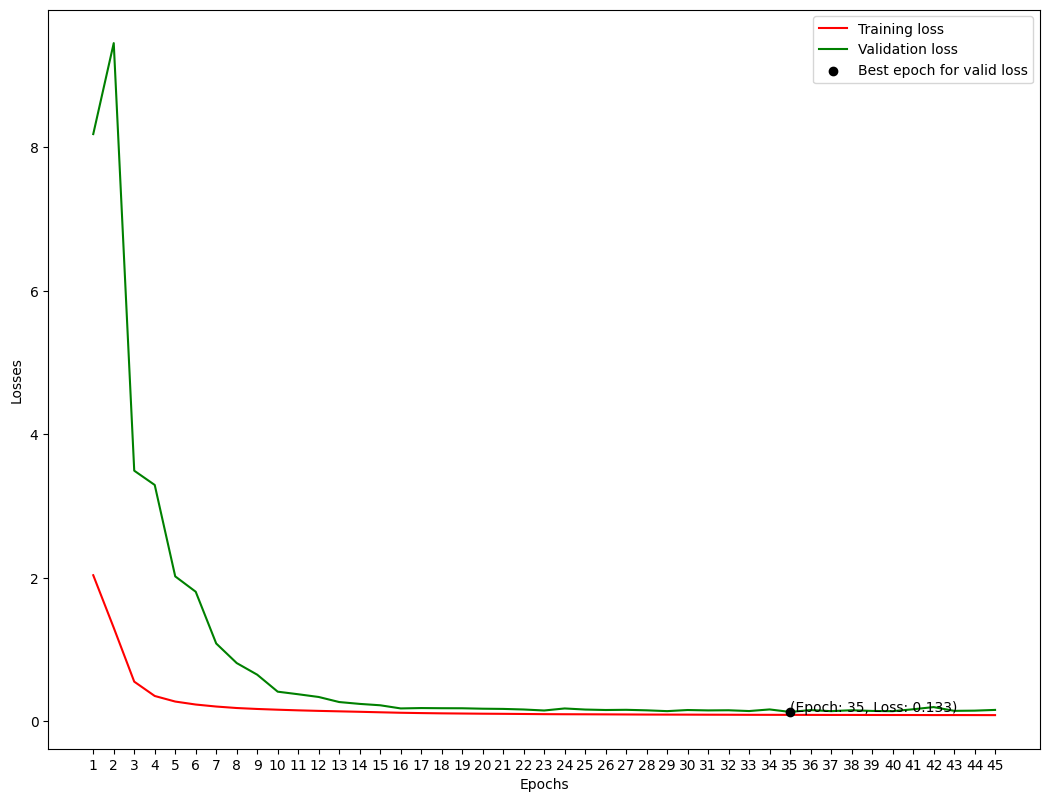

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/1228 [00:00<?, ?it/s]

f1: 0.9862520706413248
accuracy: 0.9862574438845625
precision: 0.9866555544460289
recall: 0.9862574438845625


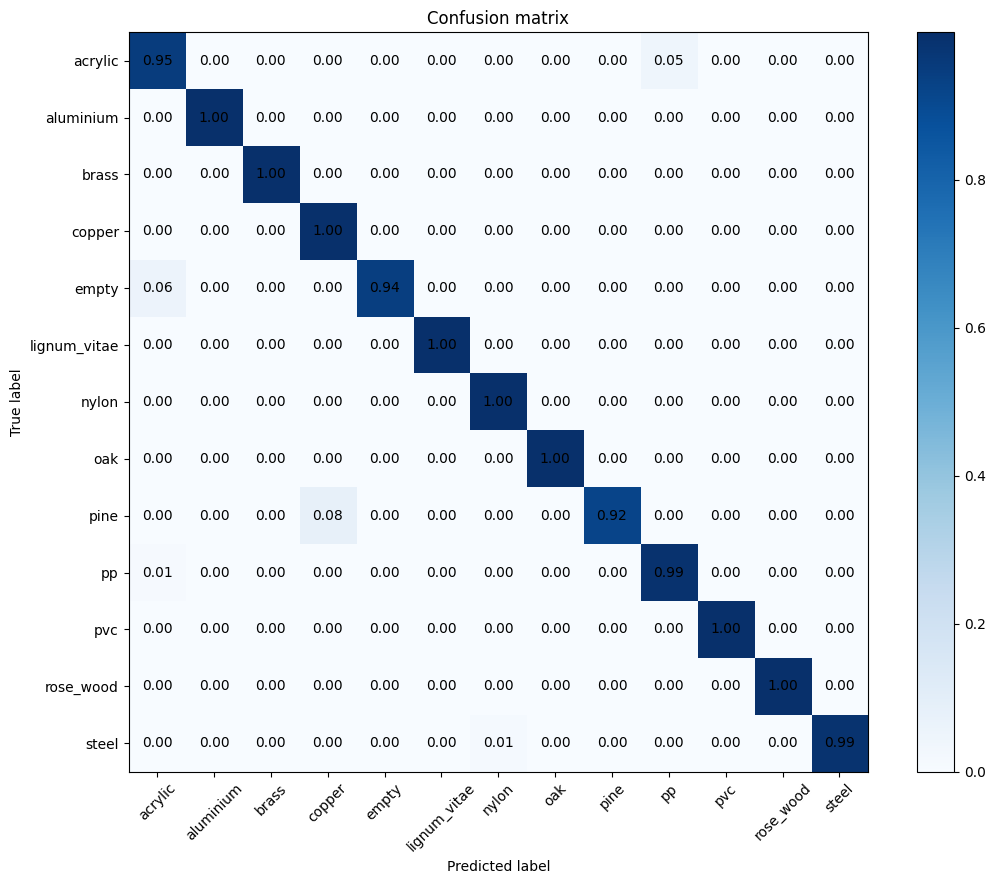

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

BOX


The lowest loss is at the epoch 35


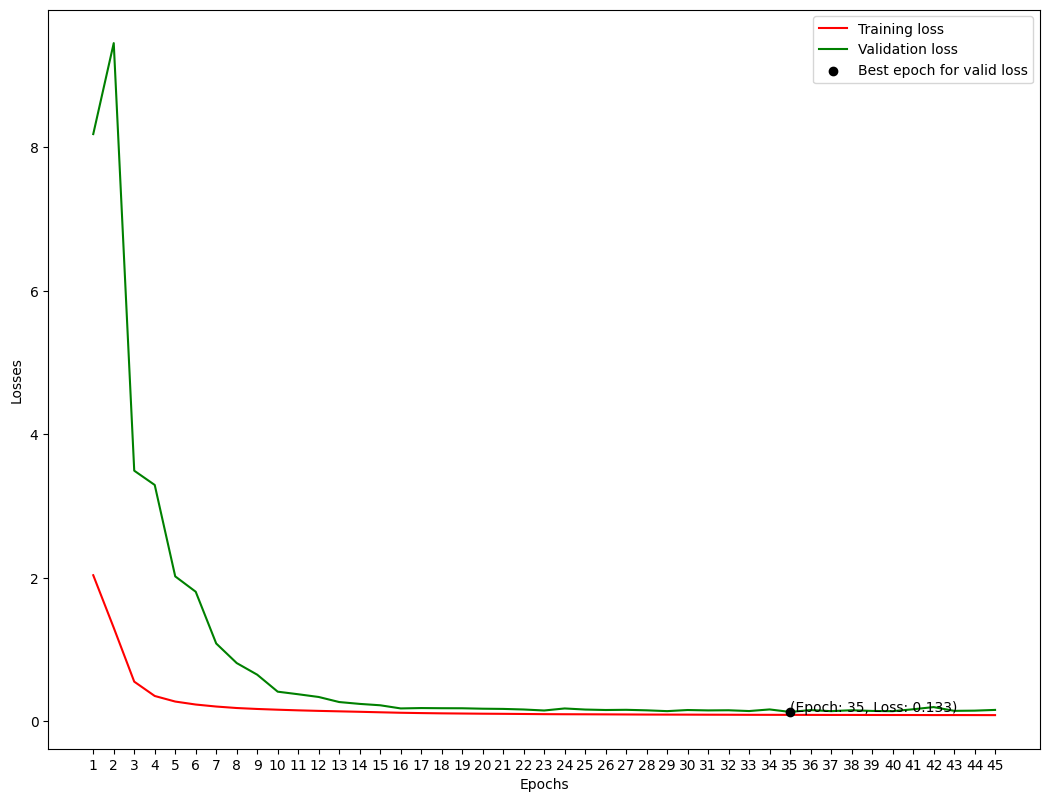

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/659 [00:00<?, ?it/s]

f1: 0.9890187578187267
accuracy: 0.9890459028831563
precision: 0.9895769349452677
recall: 0.9890459028831563


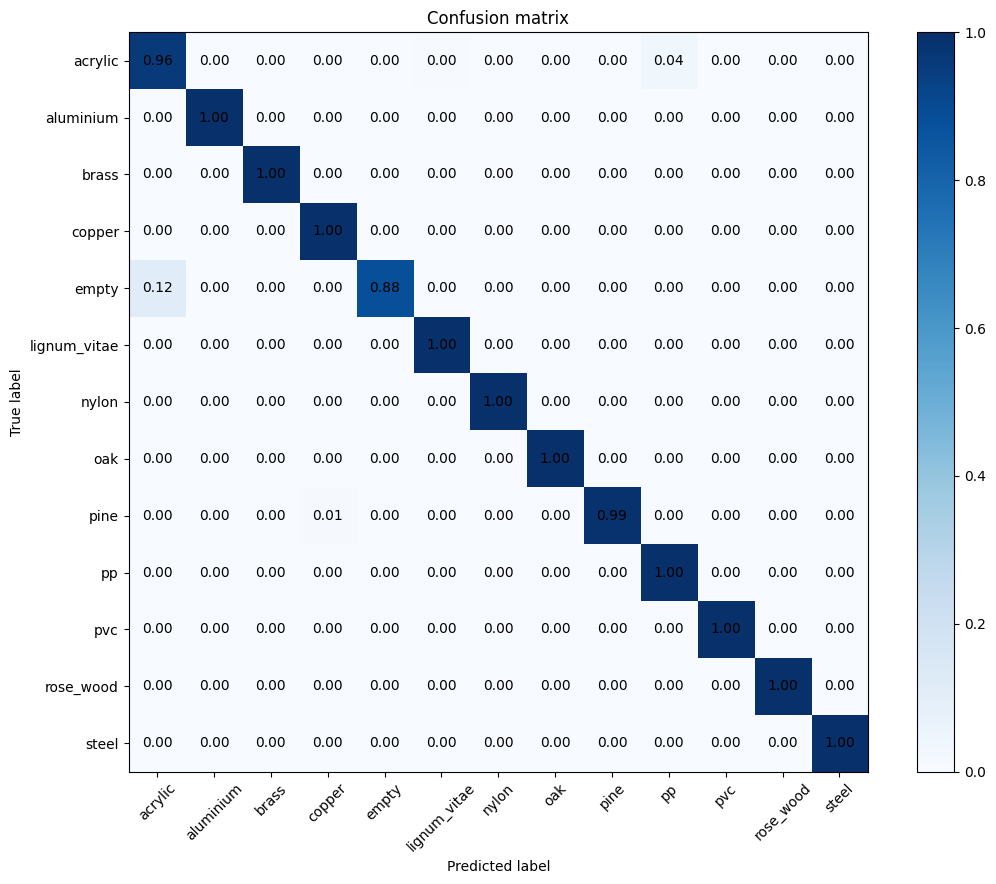

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

NOT_BOX


The lowest loss is at the epoch 35


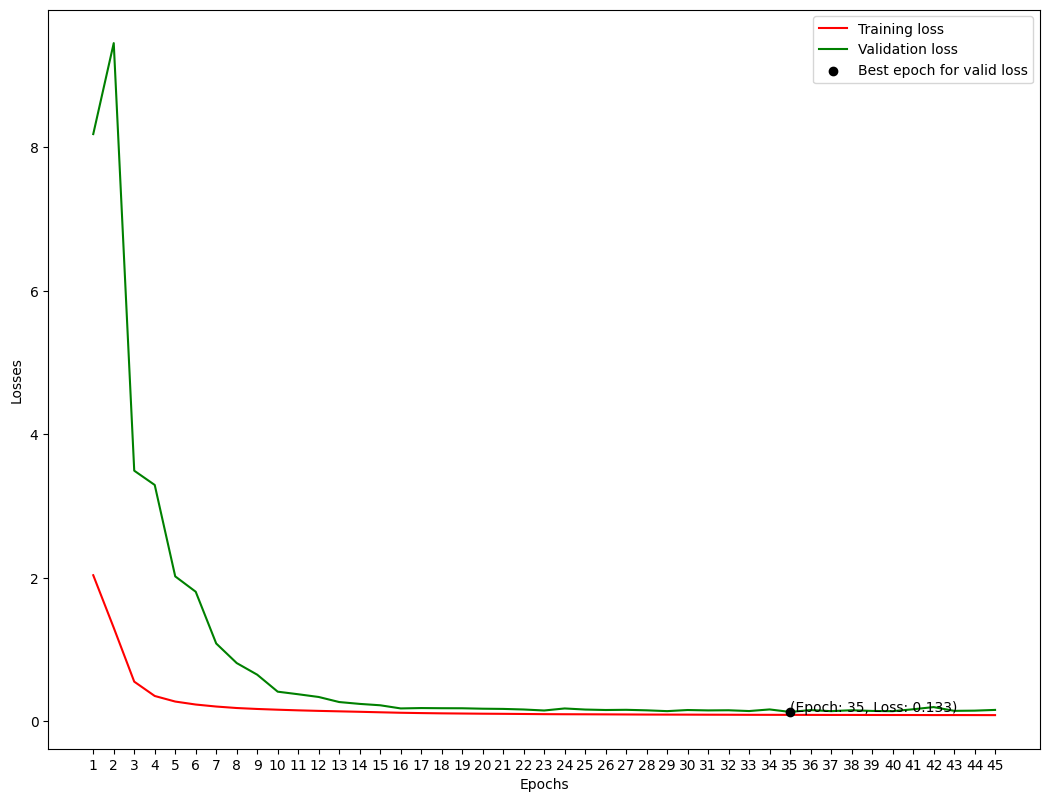

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/569 [00:00<?, ?it/s]

f1: 0.9829952242028255
accuracy: 0.9830275733274745
precision: 0.9840358676014083
recall: 0.9830275733274745


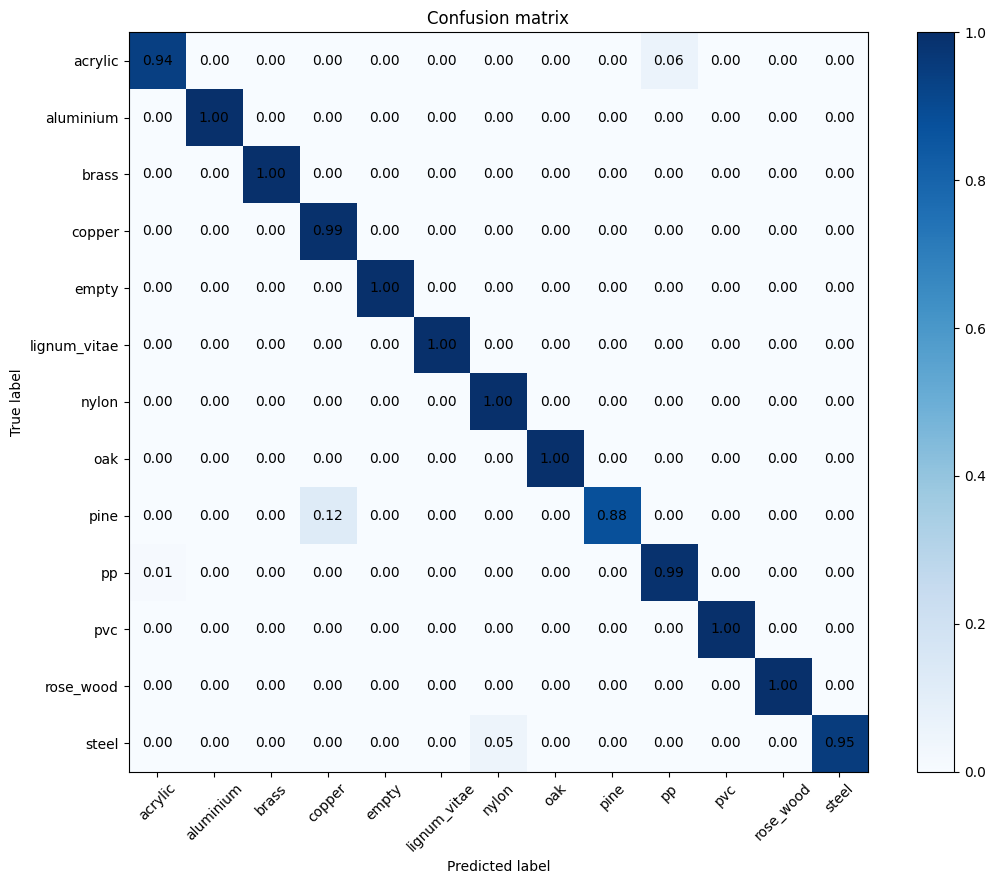

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

# Results
This section shows the results obtained with previous versions of the model. Without box are the tests performed on unshielded data while with box represent the tests performed on shielded data

## Without Box

### Conv1d
Test performed with the CNN 1D

#### Phase
Test using as feature only phase


The lowest loss is at the epoch 7


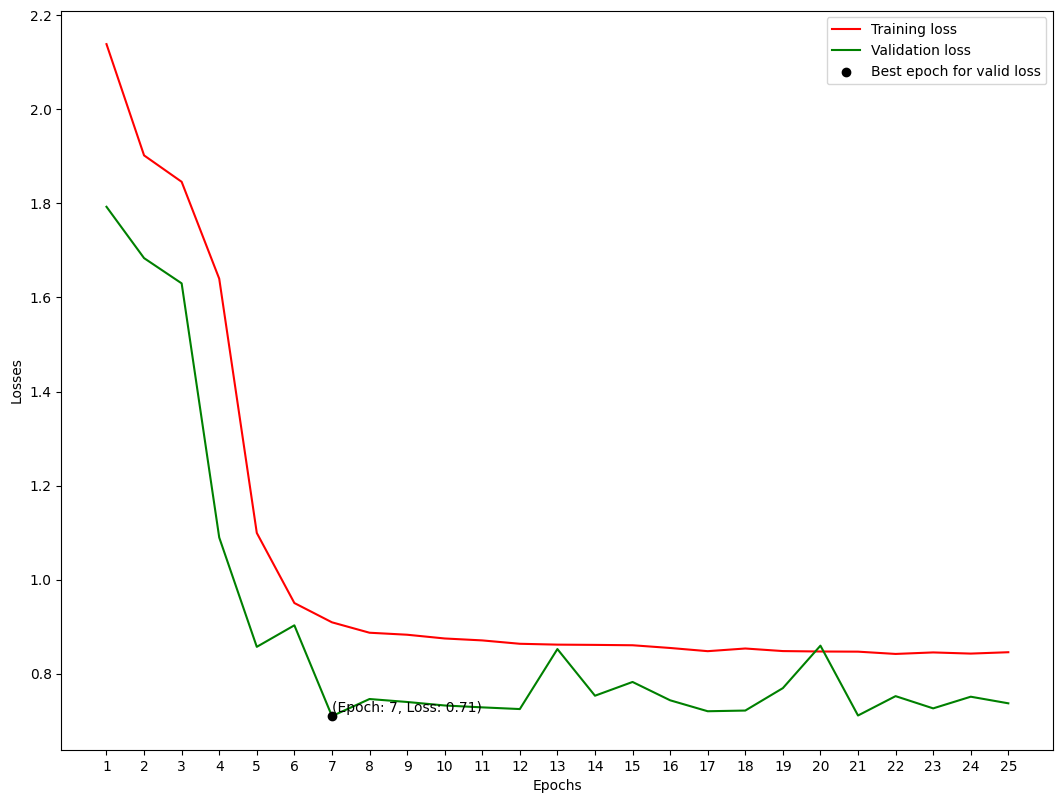

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/285 [00:00<?, ?it/s]

f1: 0.5434530595142356
accuracy: 0.5983192354168956
precision: 0.64901941631514
recall: 0.5983192354168956


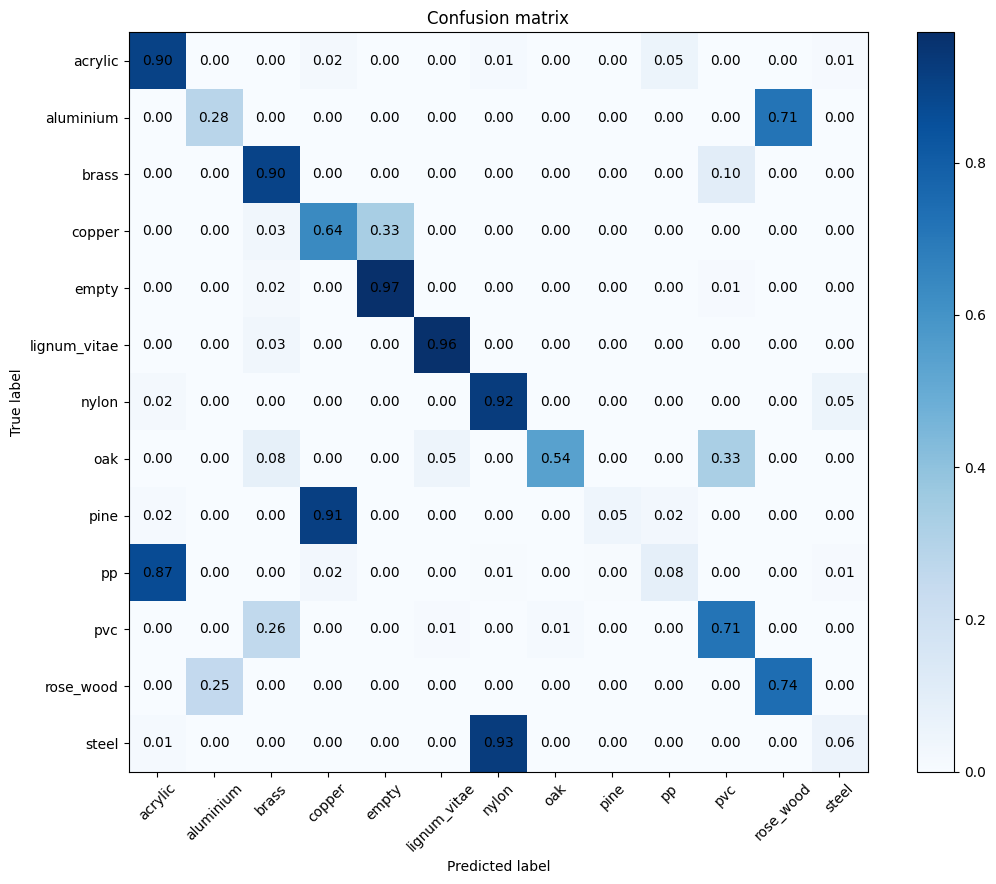

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

#### Amplitude
Test using as feature only amplitude


The lowest loss is at the epoch 16


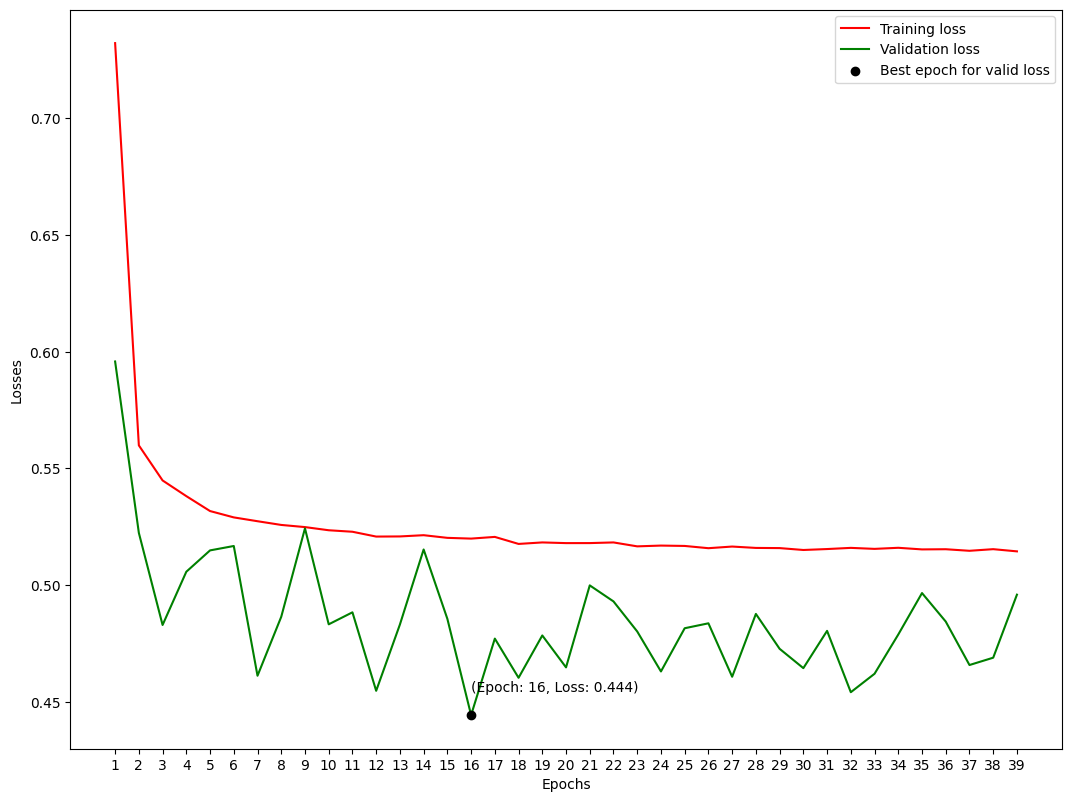

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/285 [00:00<?, ?it/s]

f1: 0.6581809788875282
accuracy: 0.6832088322531034
precision: 0.7108079069263795
recall: 0.6832088322531034


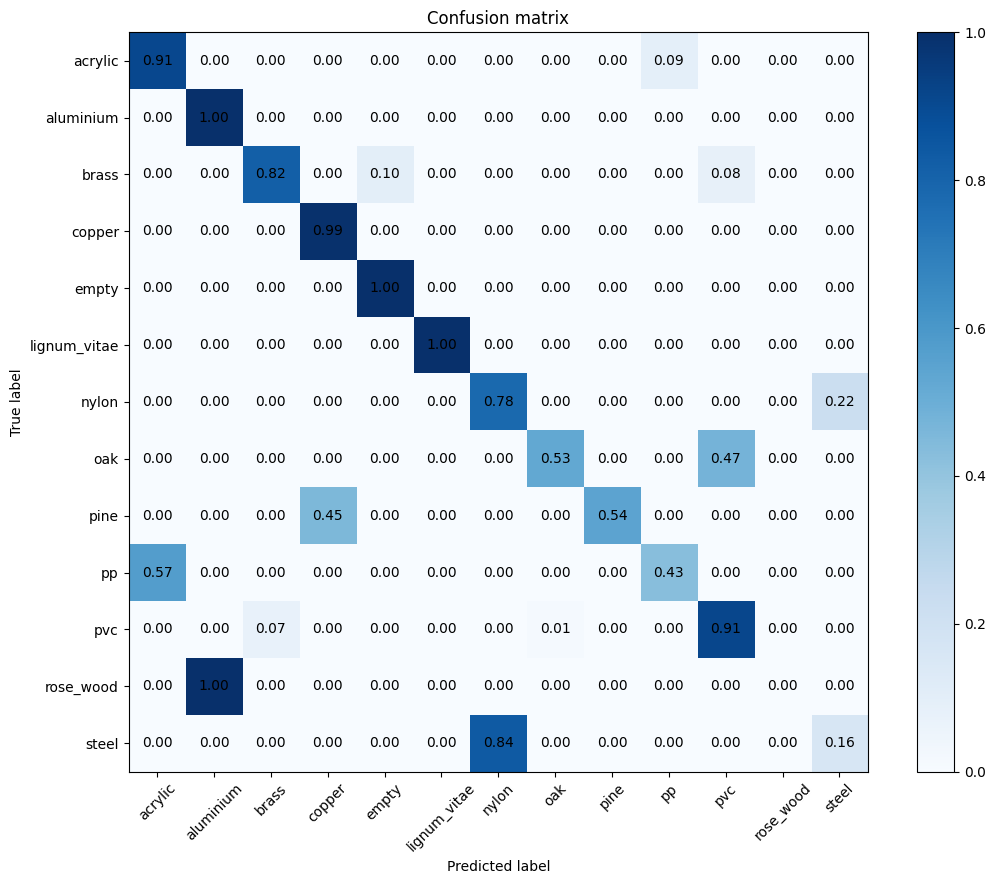

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

#### Amplitude + Phase
Test using as features amplitude and phase


The lowest loss is at the epoch 9


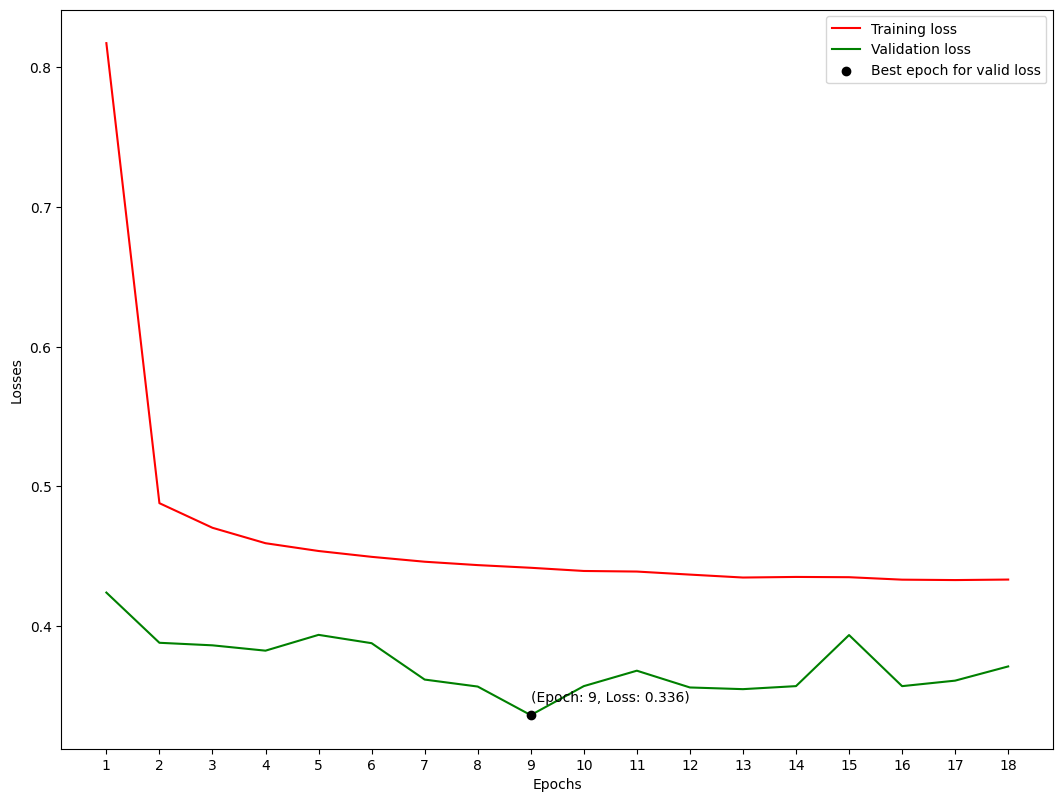

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/285 [00:00<?, ?it/s]

f1: 0.7589916608233984
accuracy: 0.7853729539712183
precision: 0.7891795963125715
recall: 0.7853729539712183


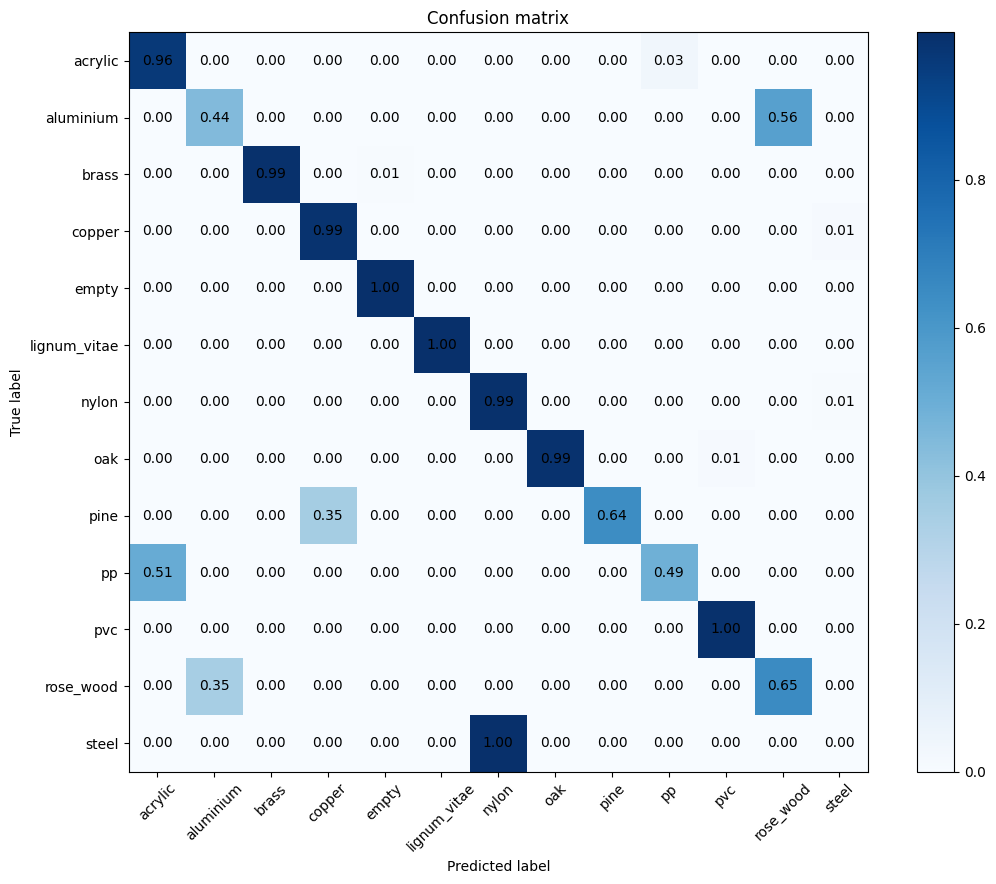

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)

plt.colorbar()
plt.show()

### Conv2d
Test performed with the CNN 2D

#### Phase
Test using as feature only phase


The lowest loss is at the epoch 5


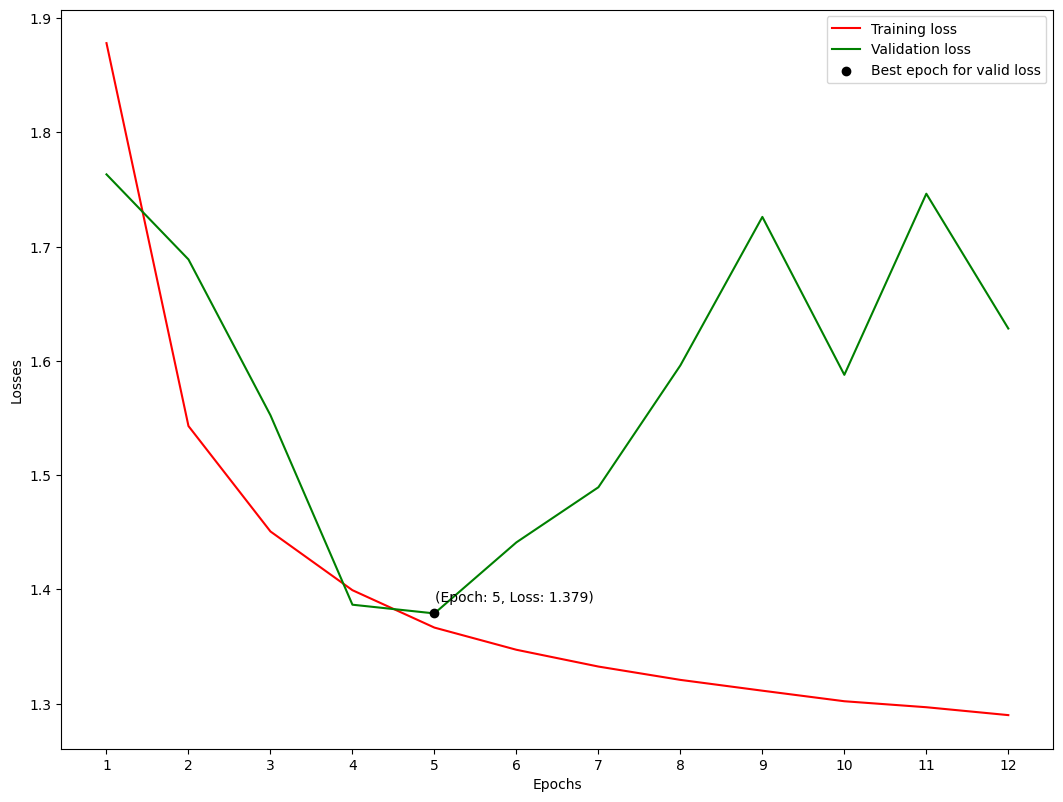

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/285 [00:00<?, ?it/s]

f1: 0.2784072499058757
accuracy: 0.32986378117104254
precision: 0.31472460401172736
recall: 0.32986378117104254


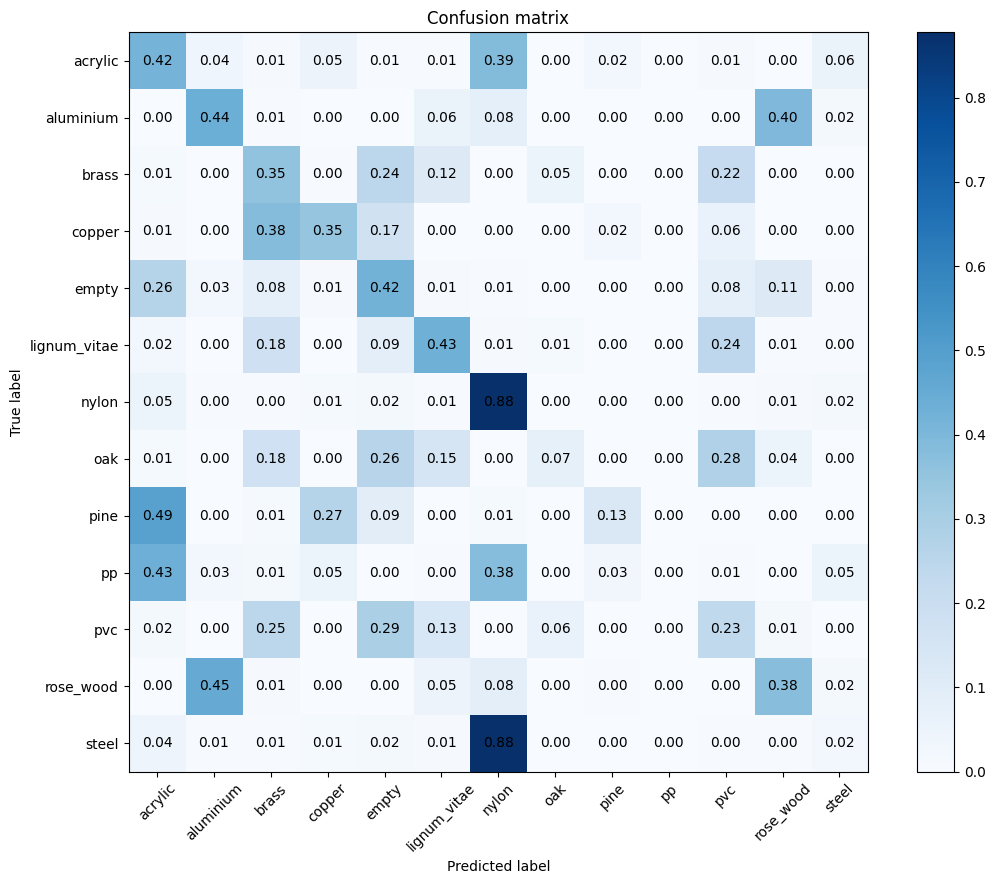

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

#### Amplitude
Test using as feature only amplitude


The lowest loss is at the epoch 34


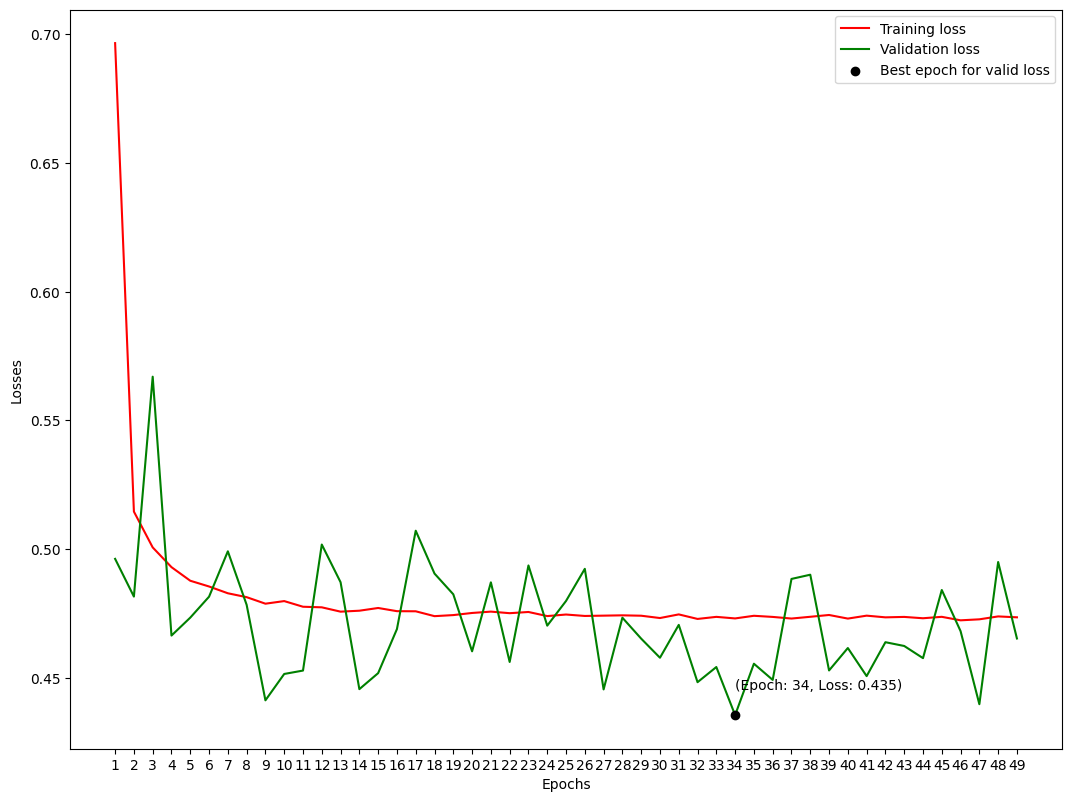

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/285 [00:00<?, ?it/s]

f1: 0.7062201019530592
accuracy: 0.7108096232011425
precision: 0.7501578315077174
recall: 0.7108096232011425


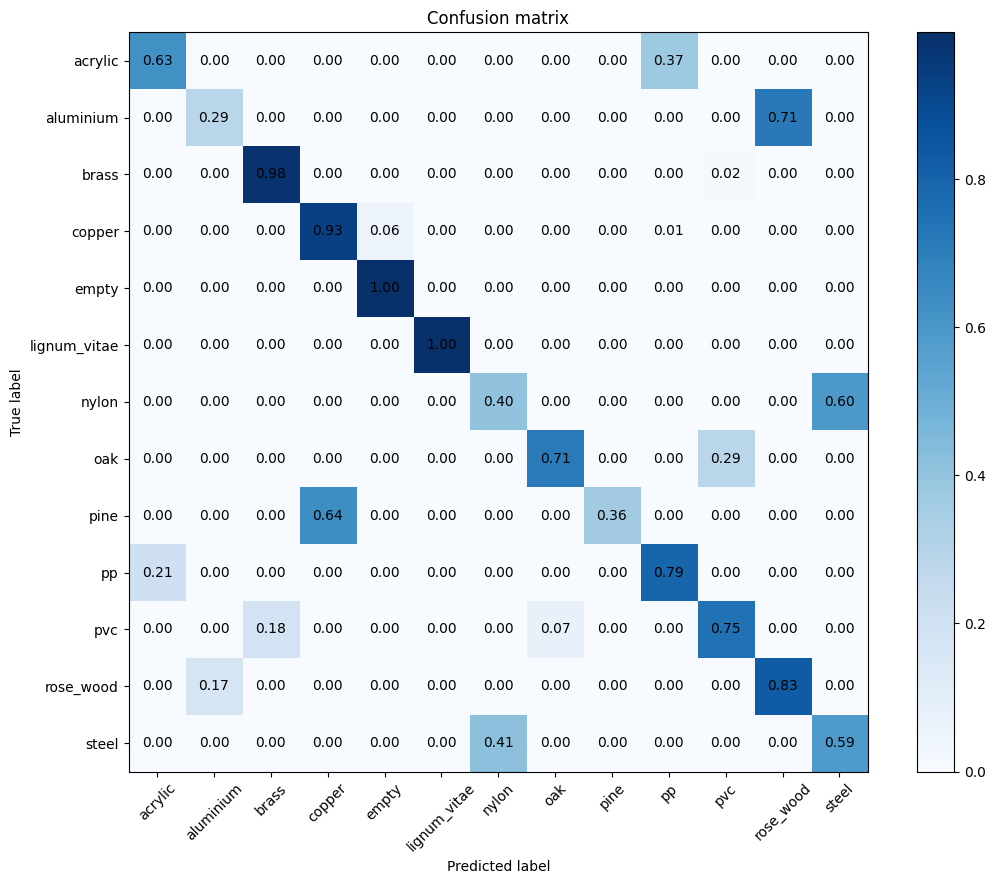

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

#### Amplitude + Phase
Test using as features amplitude and phase


The lowest loss is at the epoch 22


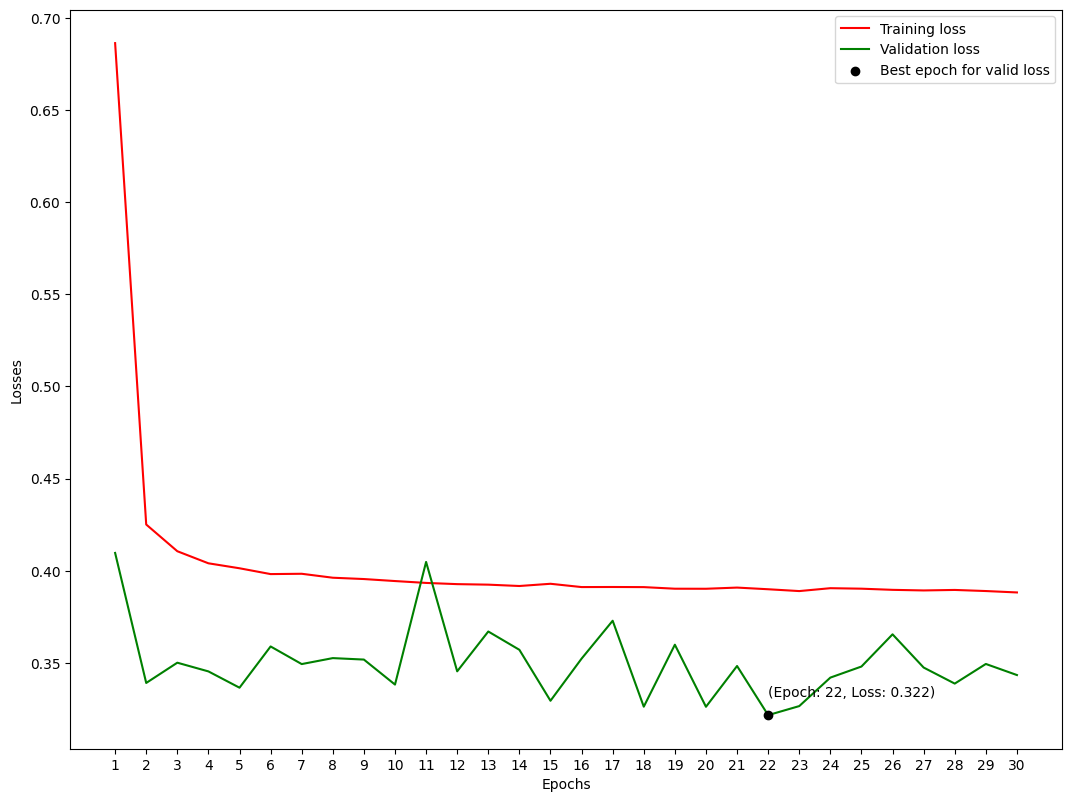

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/285 [00:00<?, ?it/s]

f1: 0.7822680493896654
accuracy: 0.7945182906734044
precision: 0.8021420830695098
recall: 0.7945182906734044


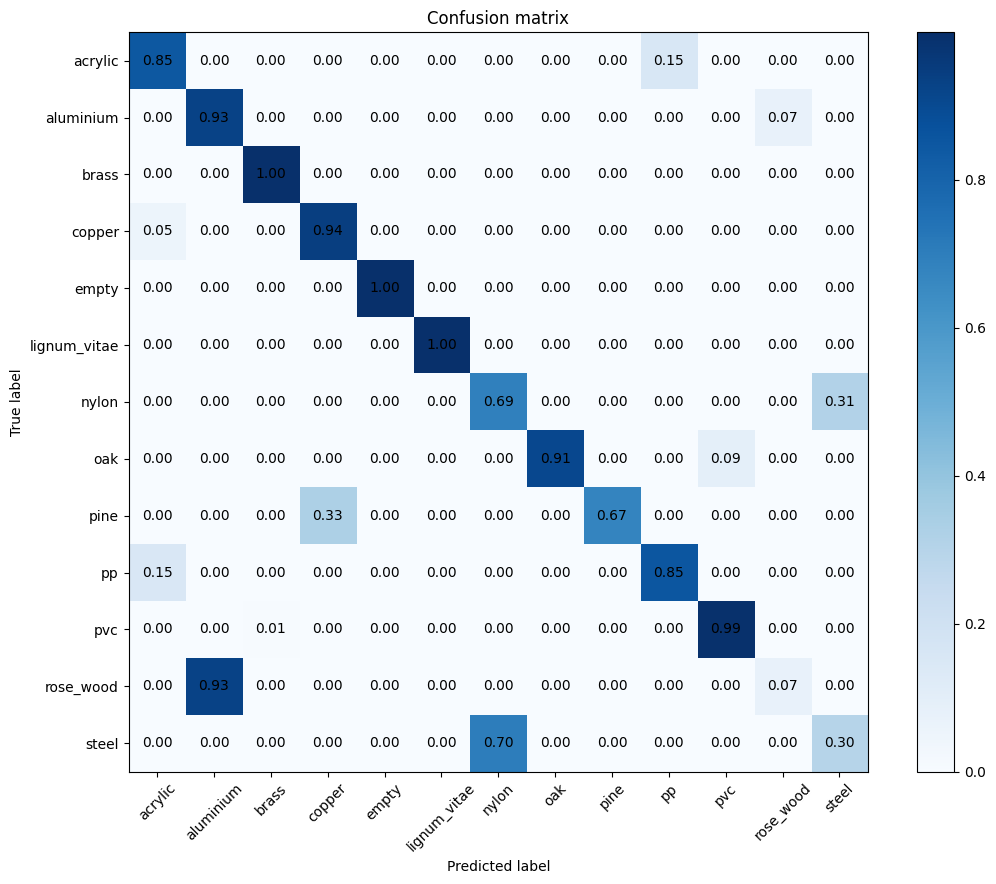

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)

plt.colorbar()
plt.show()

#### Amplitude + RSSI
Test using as features amplitude and RSSI


The lowest loss is at the epoch 34


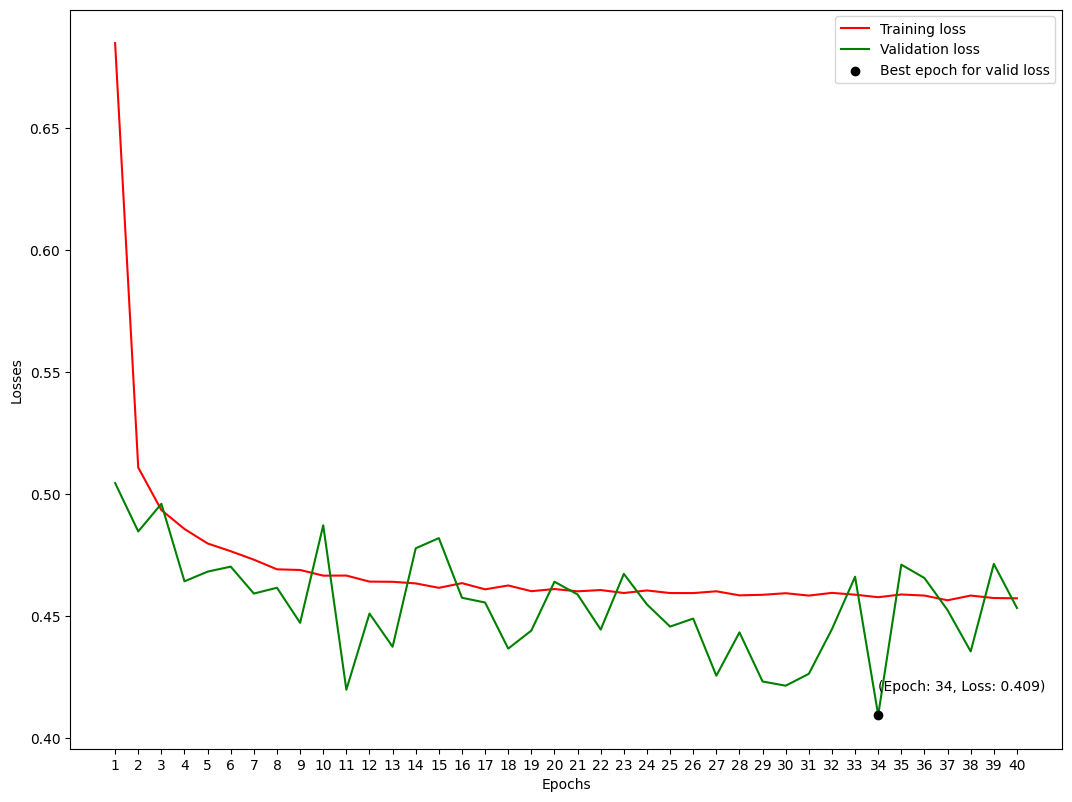

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/285 [00:00<?, ?it/s]

f1: 0.6961140093200872
accuracy: 0.7231681863122048
precision: 0.7419338498280879
recall: 0.7231681863122048


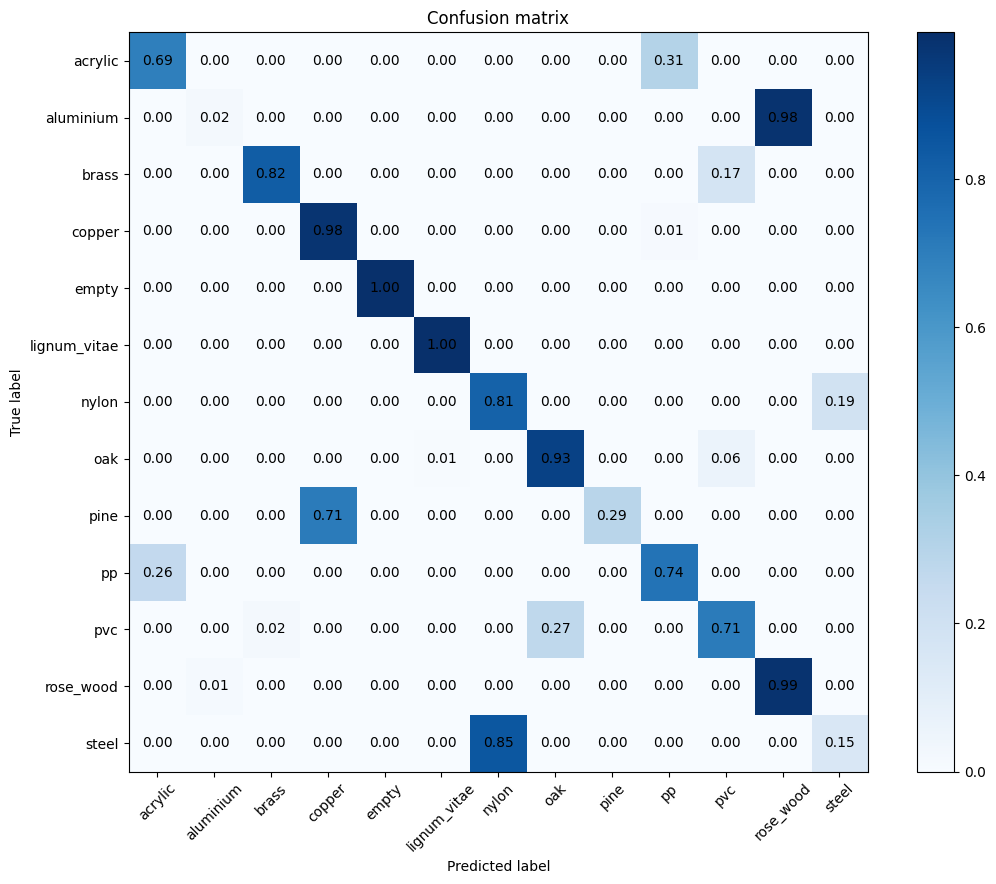

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

#### Amplitude + Phase + RSSI
Test using as features amplitude, phase and RSSI


The lowest loss is at the epoch 19


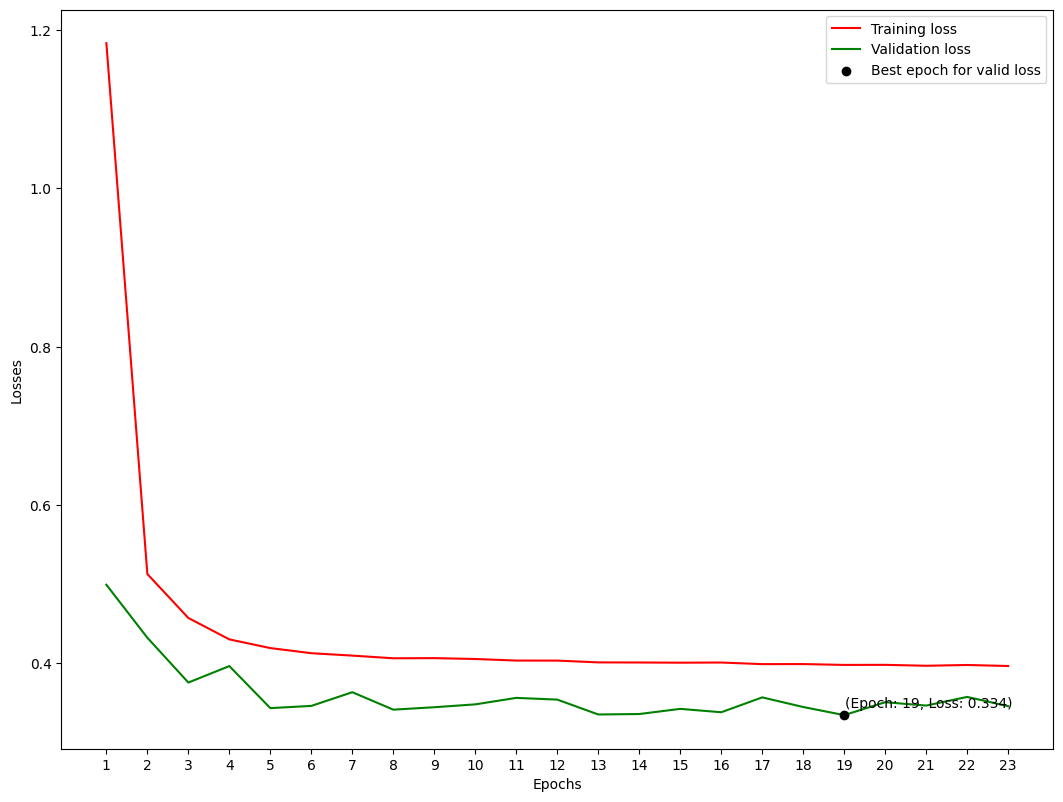

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/285 [00:00<?, ?it/s]

f1: 0.7882308322089296
accuracy: 0.829561682961661
precision: 0.7941343059582794
recall: 0.829561682961661


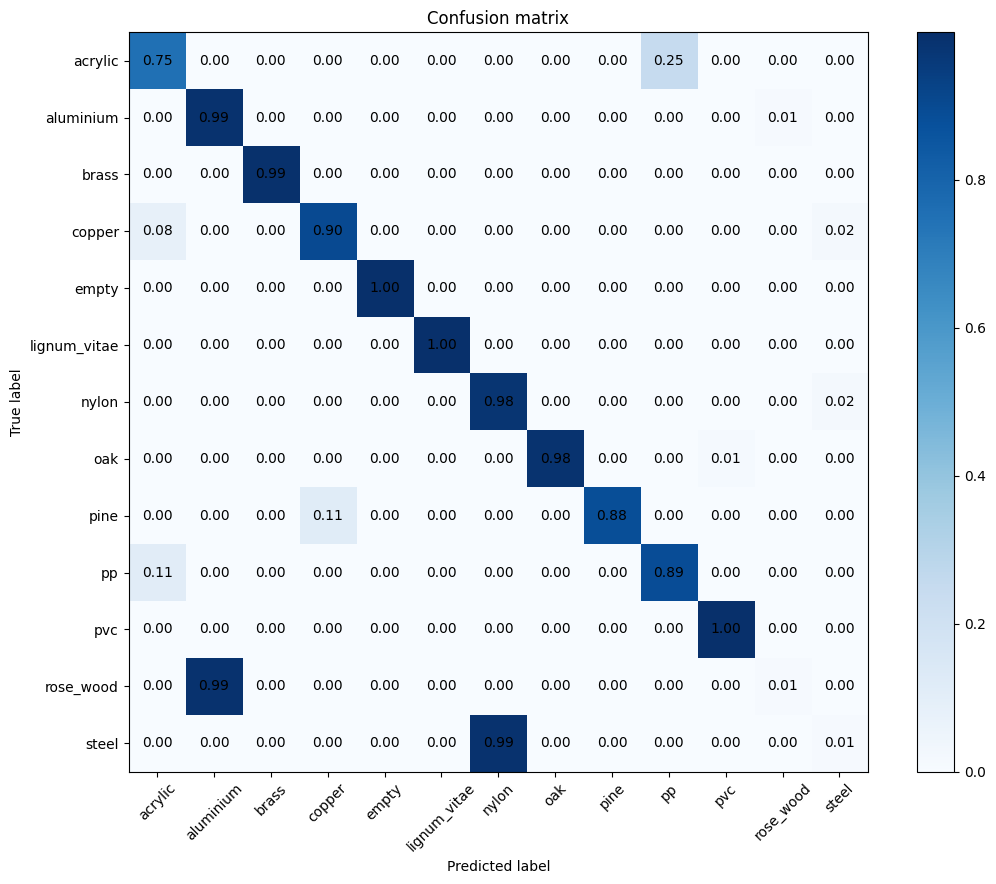

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

### Conv1d + Conv2d
Test performed with the combination of CNN 1D and CNN 2D. The features used are amplitude, phase and RSSI. Specifically, CNN1D processes the phase, while CNN 2D processes the combination of amplitude, phase and RSSI.


The lowest loss is at the epoch 15


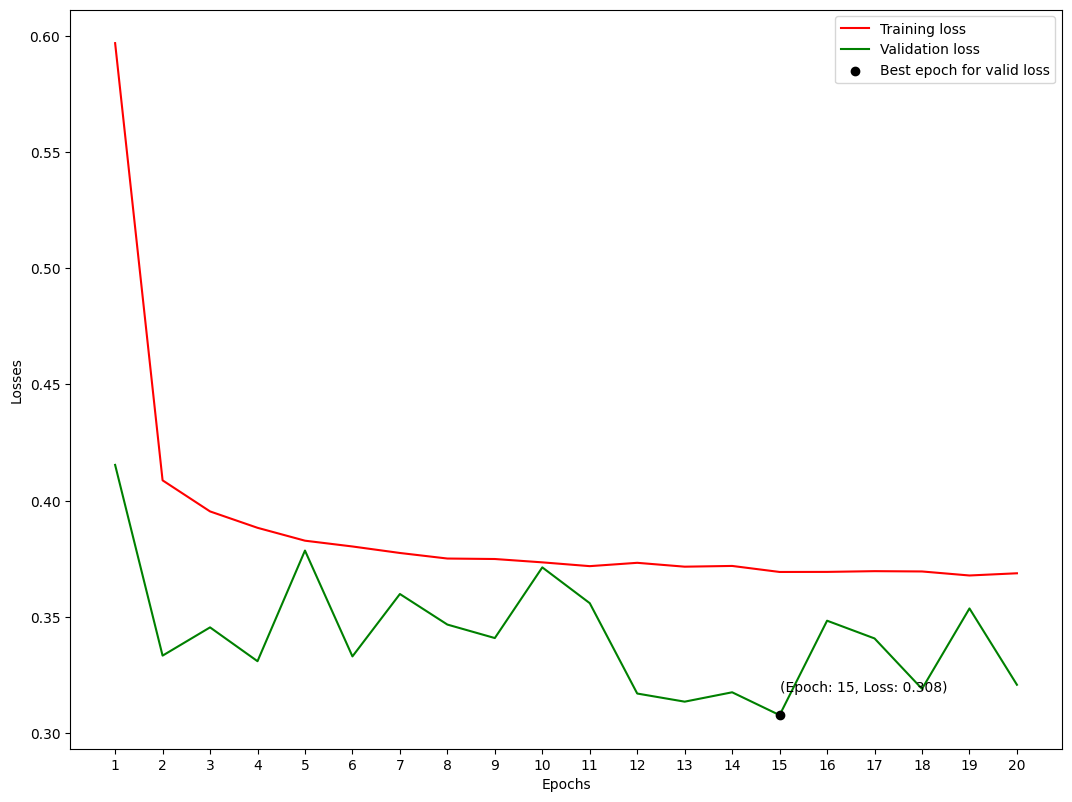

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/285 [00:00<?, ?it/s]

/usr/local/lib/python3.10/dist-packages/sklearn/metrics/_classification.py:1344: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, msg_start, len(result))


f1: 0.7978459034450158
accuracy: 0.8138251126002417
precision: 0.7962733126003595
recall: 0.8138251126002417


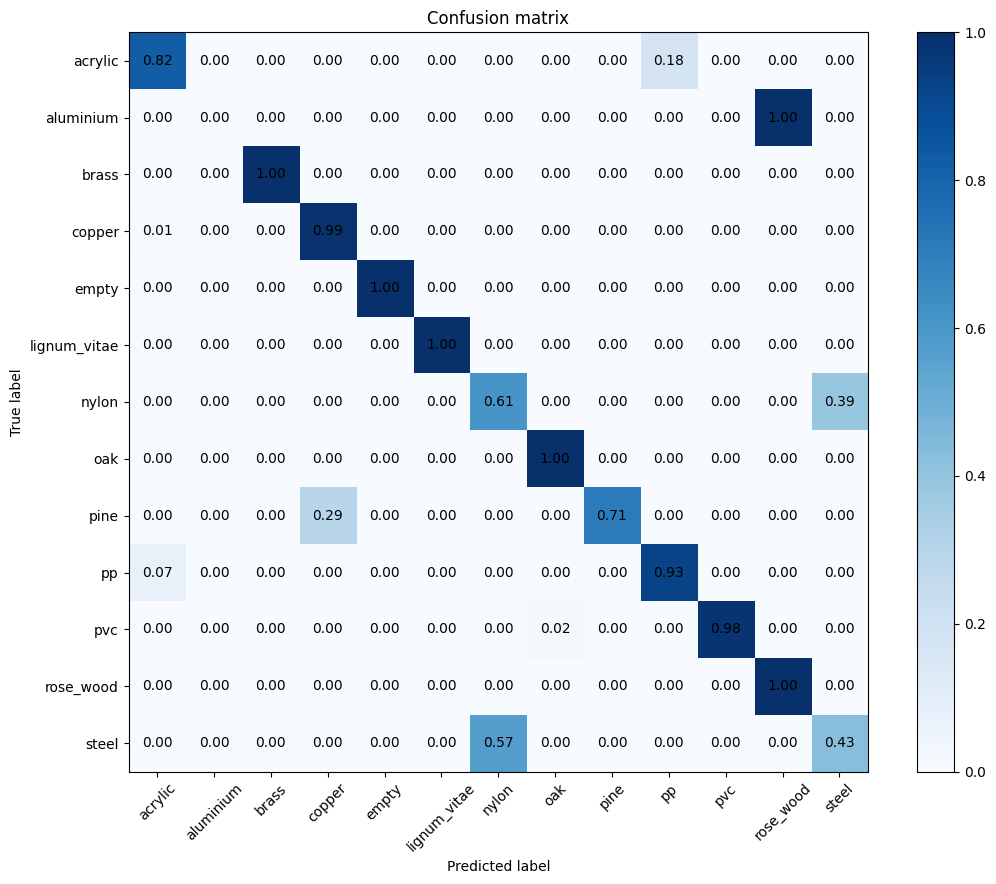

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

## With Box

### Conv1d
Test performed with the CNN 1D

#### Phase
Test using as feature only phase


The lowest loss is at the epoch 30


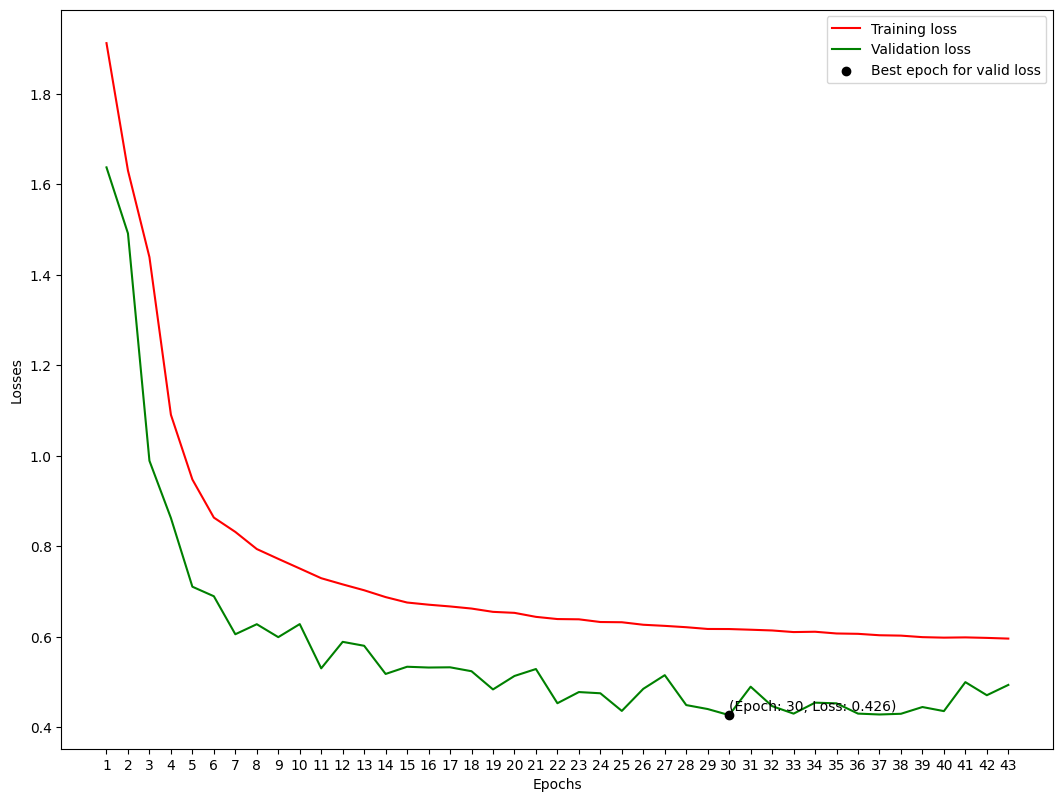

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/330 [00:00<?, ?it/s]

f1: 0.8455175255360622
accuracy: 0.847211684370258
precision: 0.8554444052672725
recall: 0.847211684370258


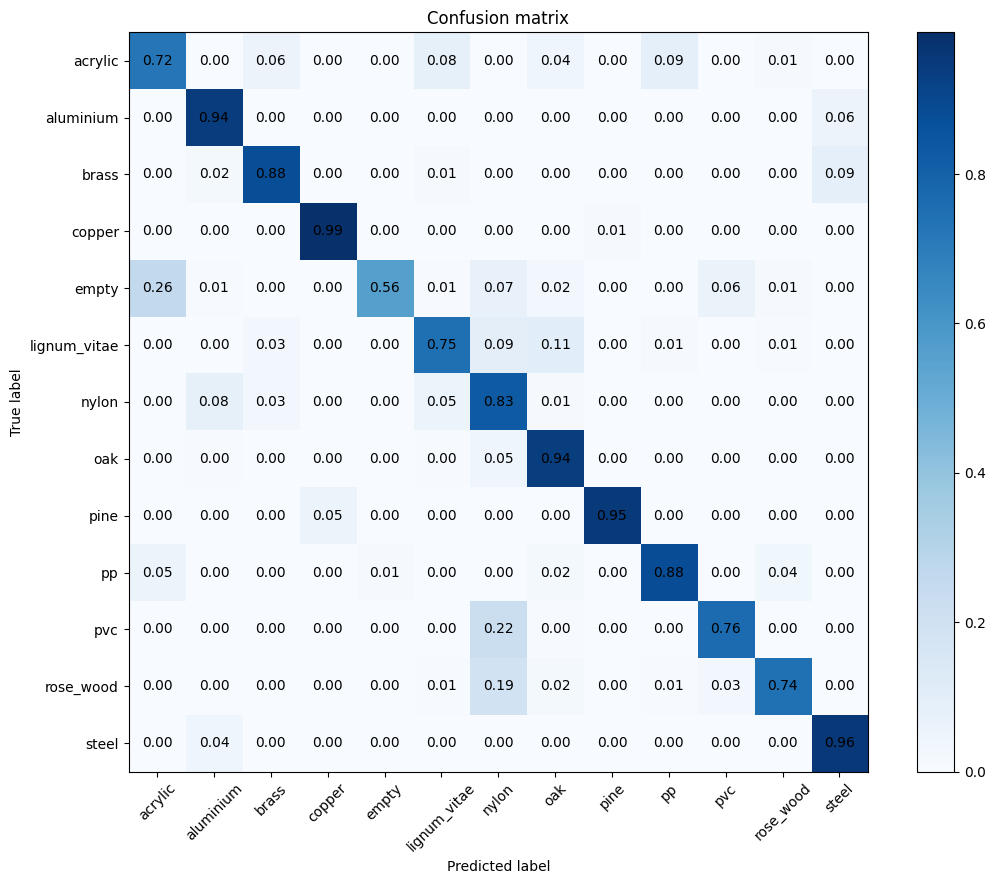

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

#### Amplitude
Test using as feature only amplitude


The lowest loss is at the epoch 31


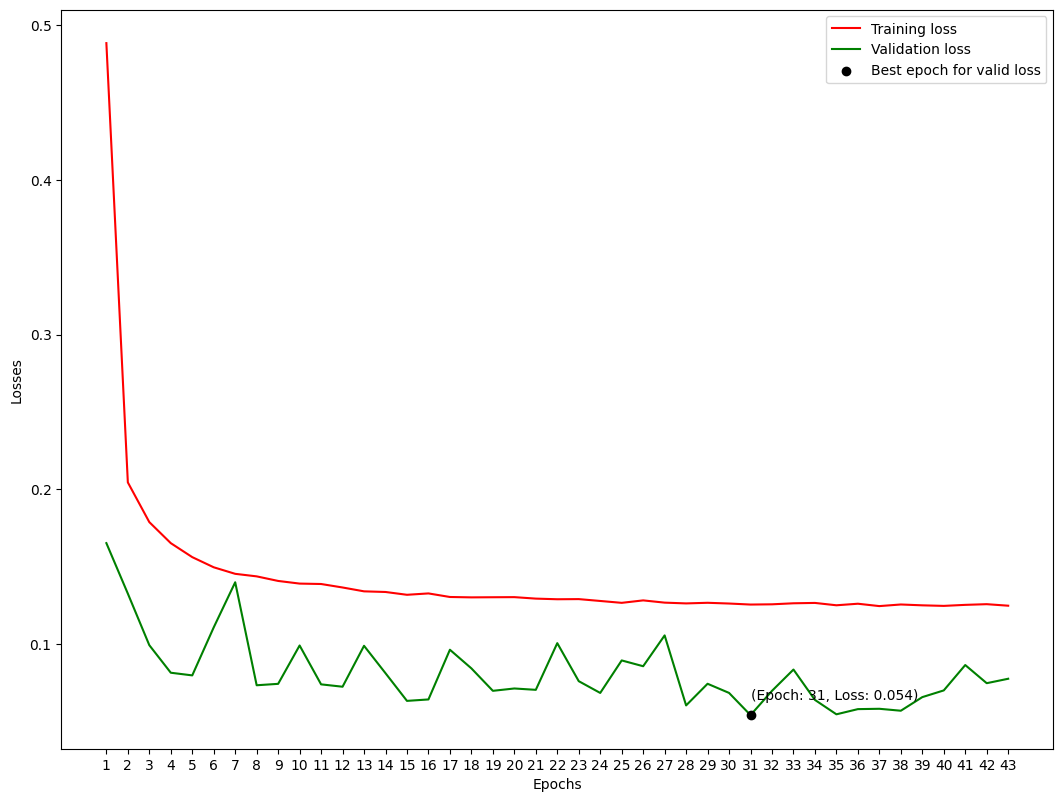

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/330 [00:00<?, ?it/s]

f1: 0.951837435029695
accuracy: 0.9542156676783005
precision: 0.9638575517880731
recall: 0.9542156676783005


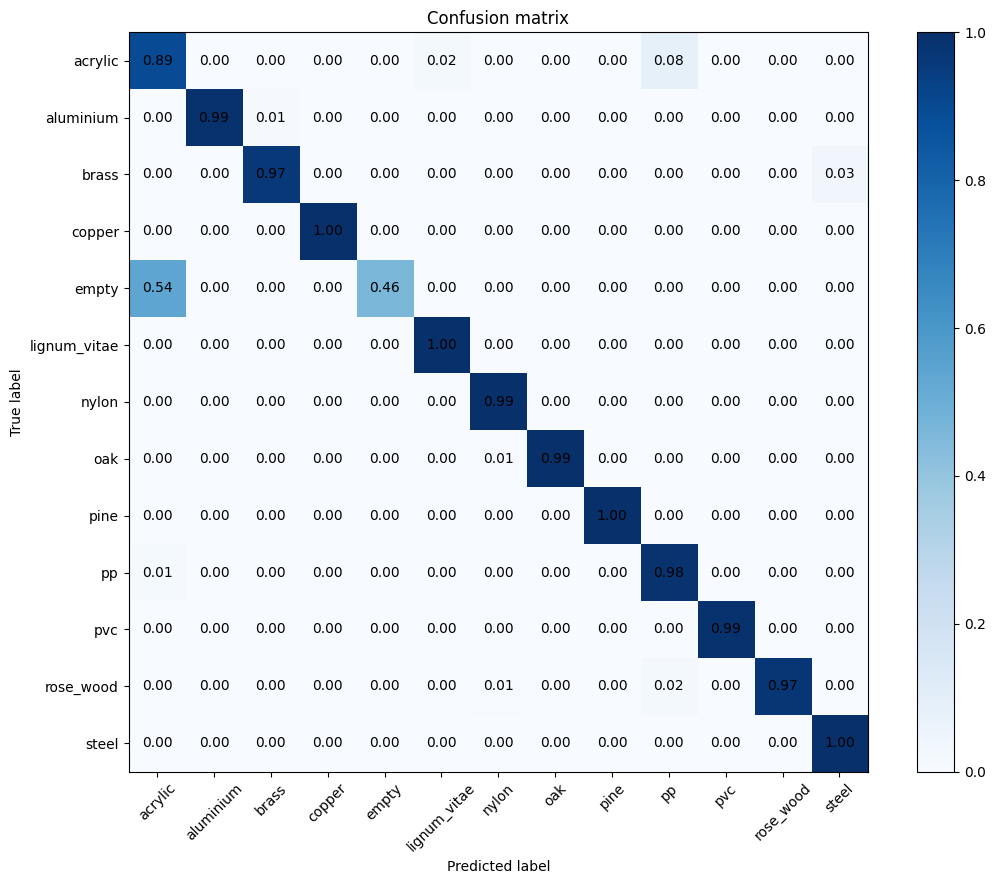

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

#### Amplitude + Phase
Test using as features amplitude and phase


The lowest loss is at the epoch 34


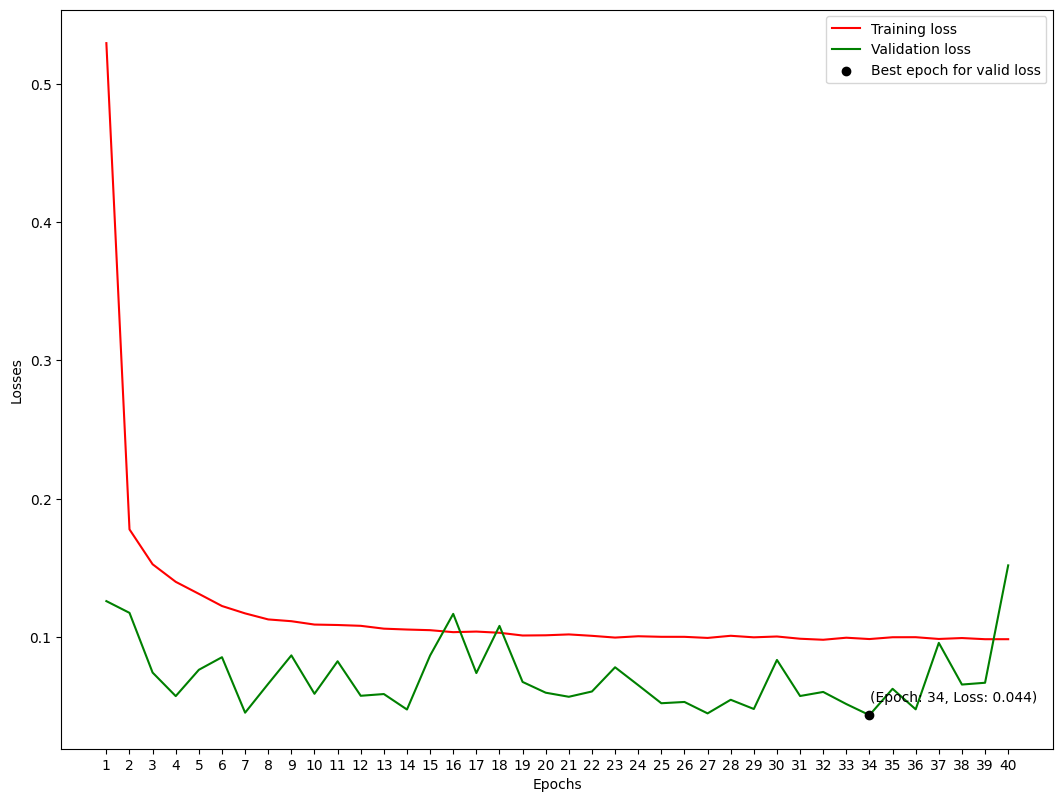

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/330 [00:00<?, ?it/s]

f1: 0.9459797869611434
accuracy: 0.9468418057663126
precision: 0.9506484157105872
recall: 0.9468418057663126


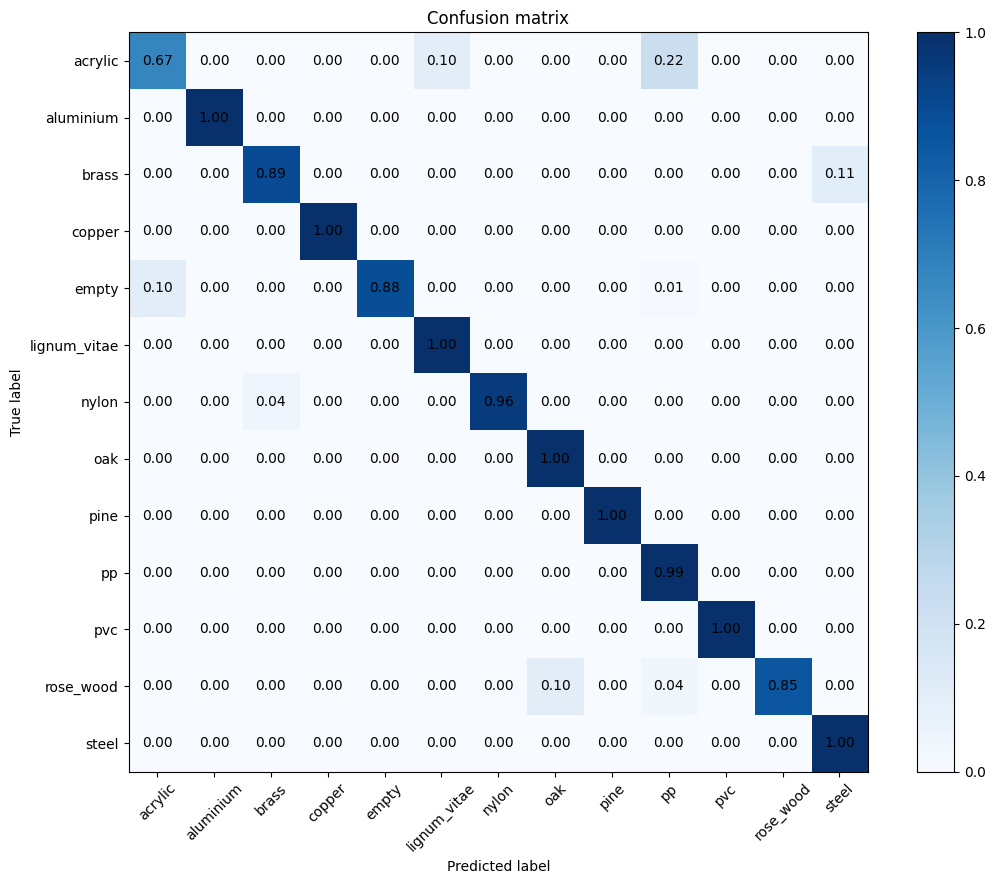

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

#### Amplitude + Phase + RSSI
Test using as features amplitude, phase and RSSI


The lowest loss is at the epoch 10


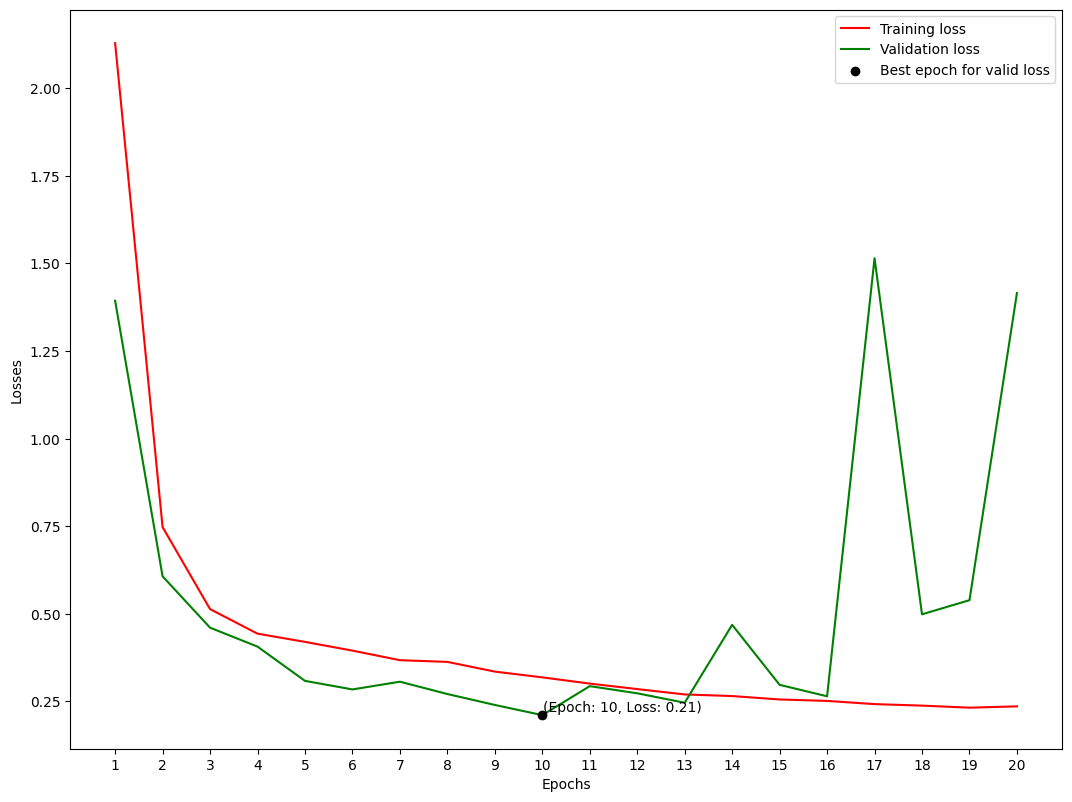

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/330 [00:00<?, ?it/s]

f1: 0.3904225872958459
accuracy: 0.4589339908952959
precision: 0.602281557553496
recall: 0.4589339908952959


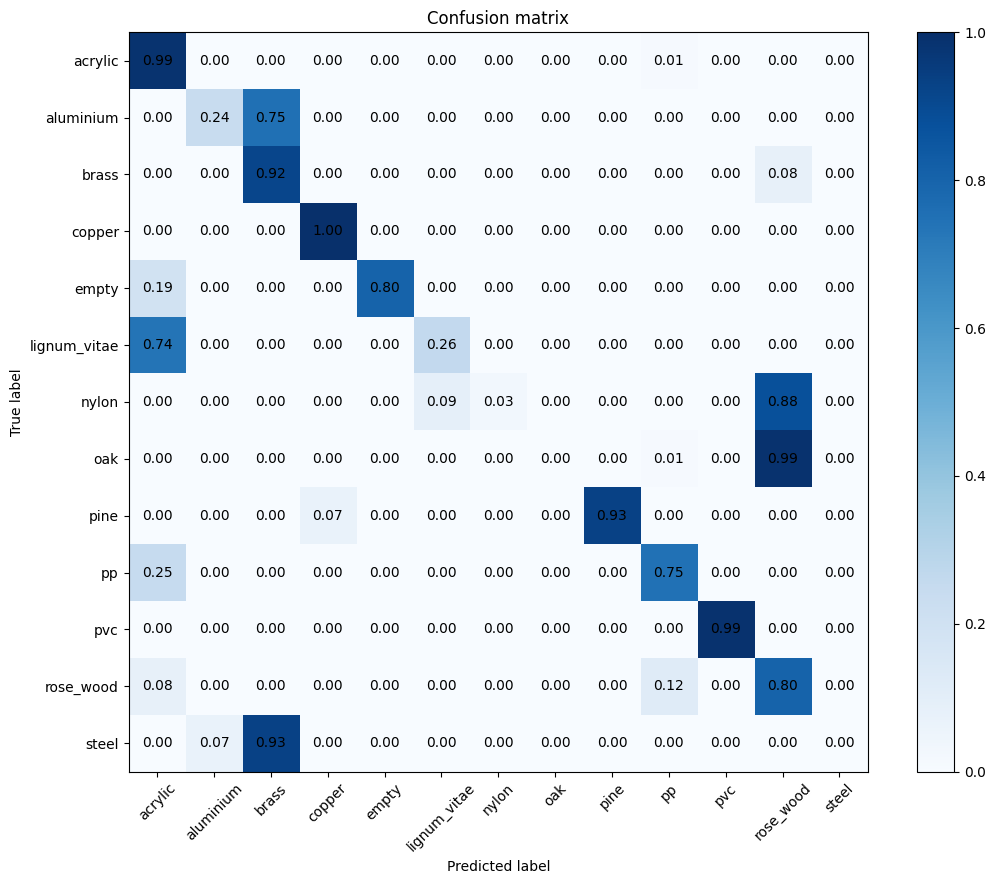

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

### Conv2d
Test performed with the CNN 2D

#### Phase
Test using as feature only phase


The lowest loss is at the epoch 1


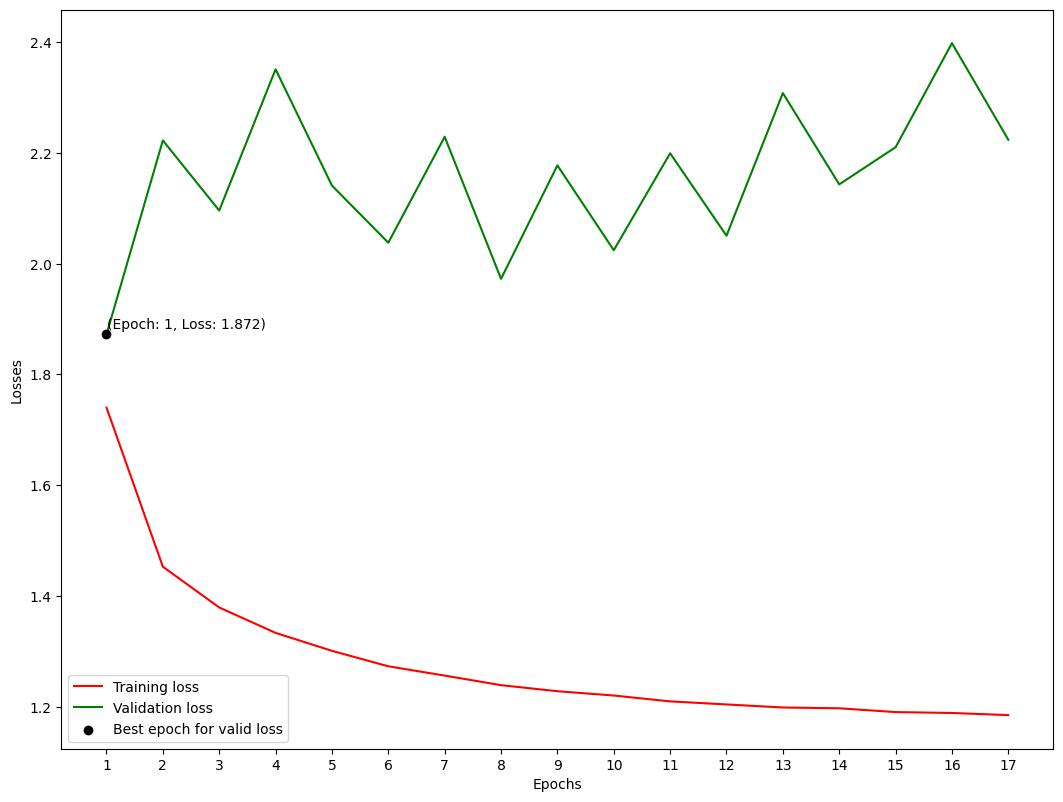

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/330 [00:00<?, ?it/s]

f1: 0.3993708565123783
accuracy: 0.4140743550834598
precision: 0.44803207550406937
recall: 0.4140743550834598


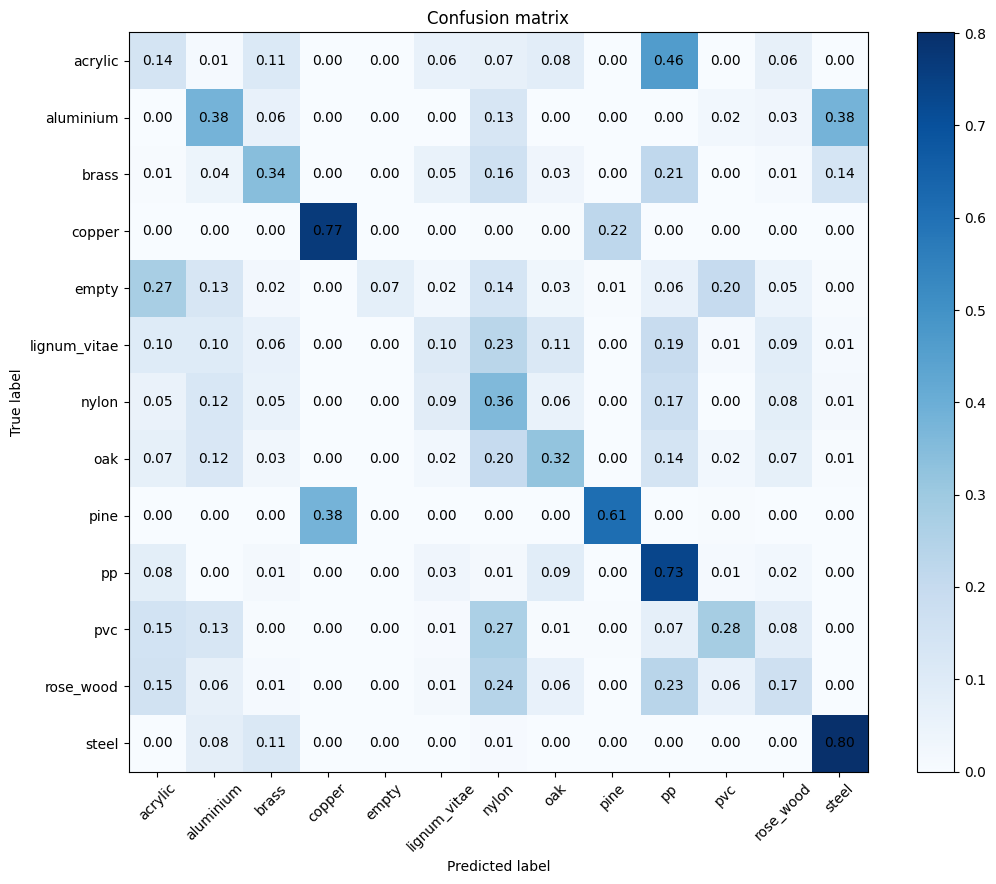

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

#### Amplitude
Test using as feature only amplitude


The lowest loss is at the epoch 11


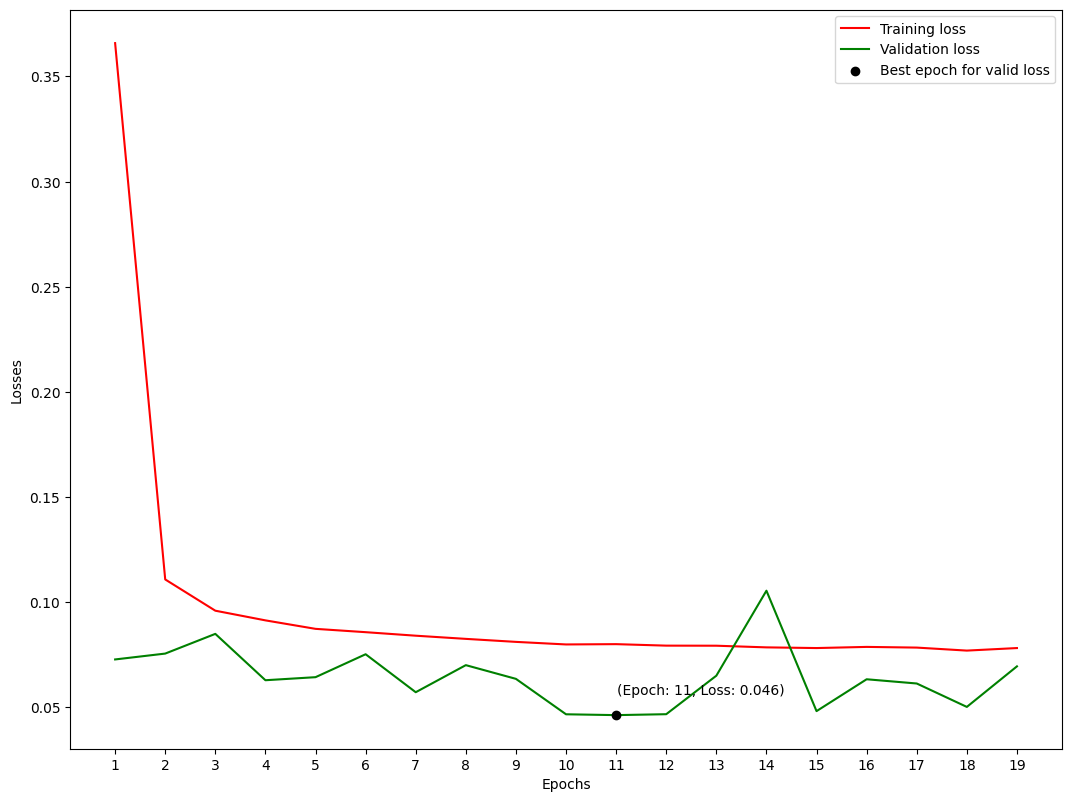

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/330 [00:00<?, ?it/s]

f1: 0.9575751748248997
accuracy: 0.9599535280728376
precision: 0.9711881321492951
recall: 0.9599535280728376


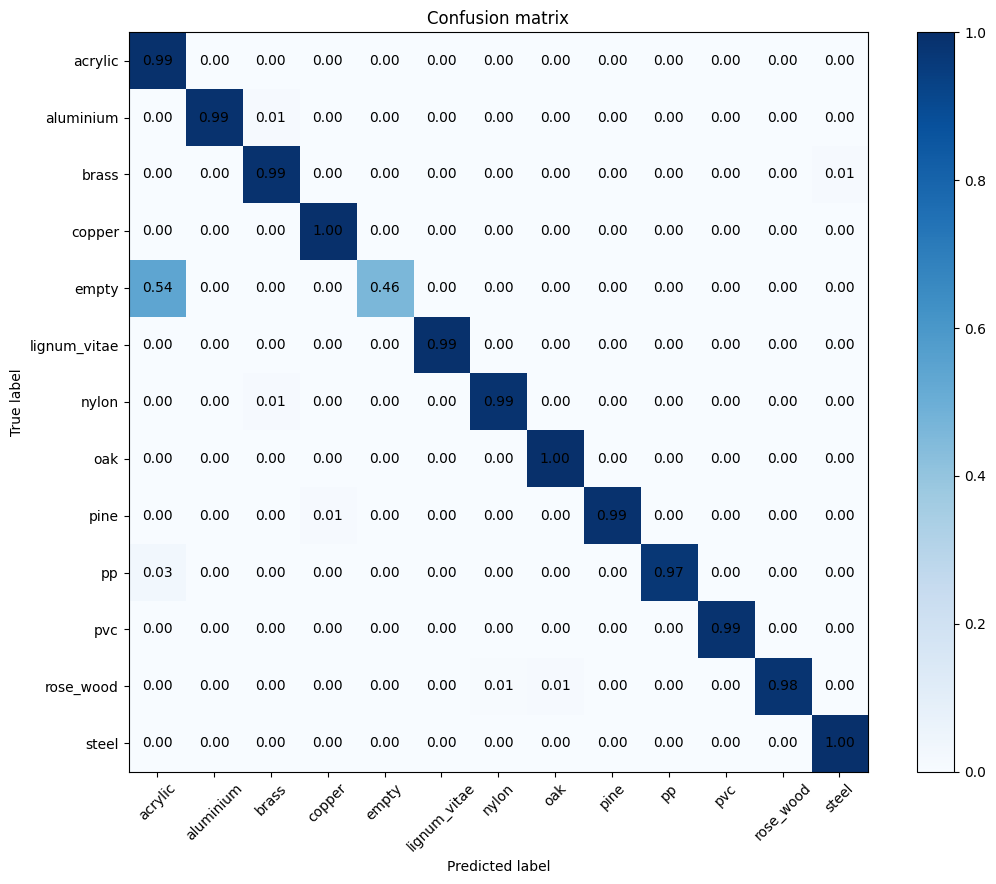

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

#### Amplitude + Phase
Test using as features amplitude and phase


The lowest loss is at the epoch 11


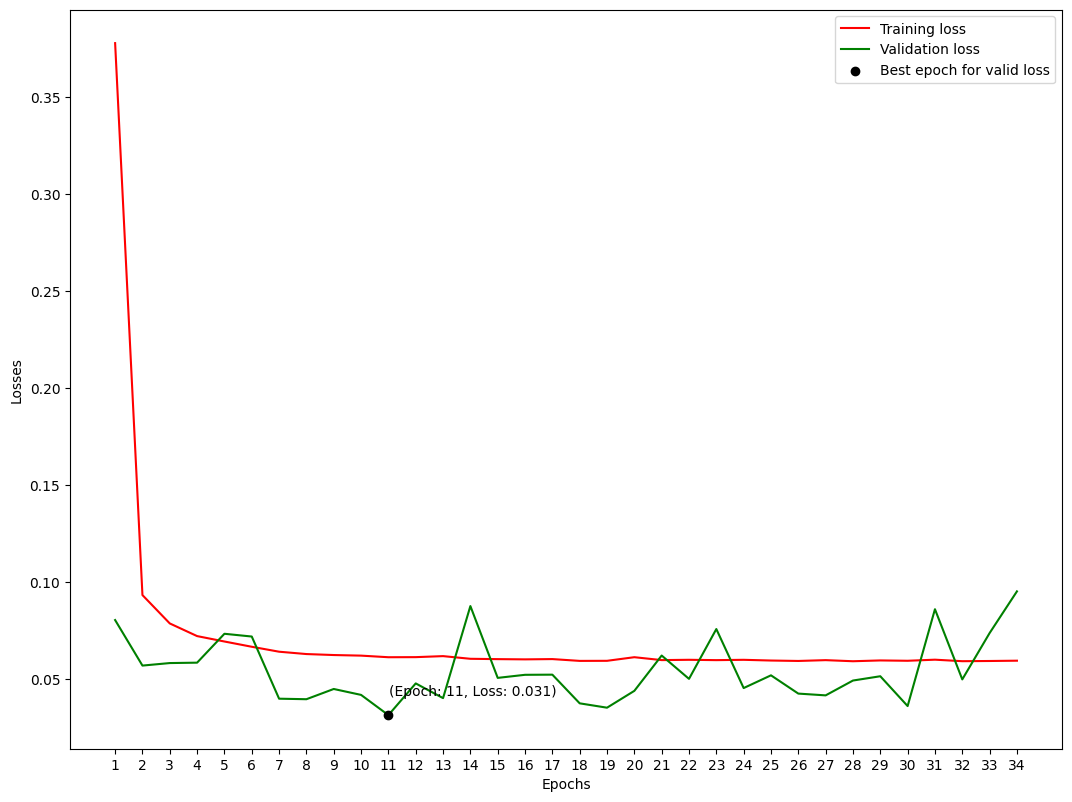

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/330 [00:00<?, ?it/s]

f1: 0.9640121234621153
accuracy: 0.9653357359635811
precision: 0.9709873702936396
recall: 0.9653357359635811


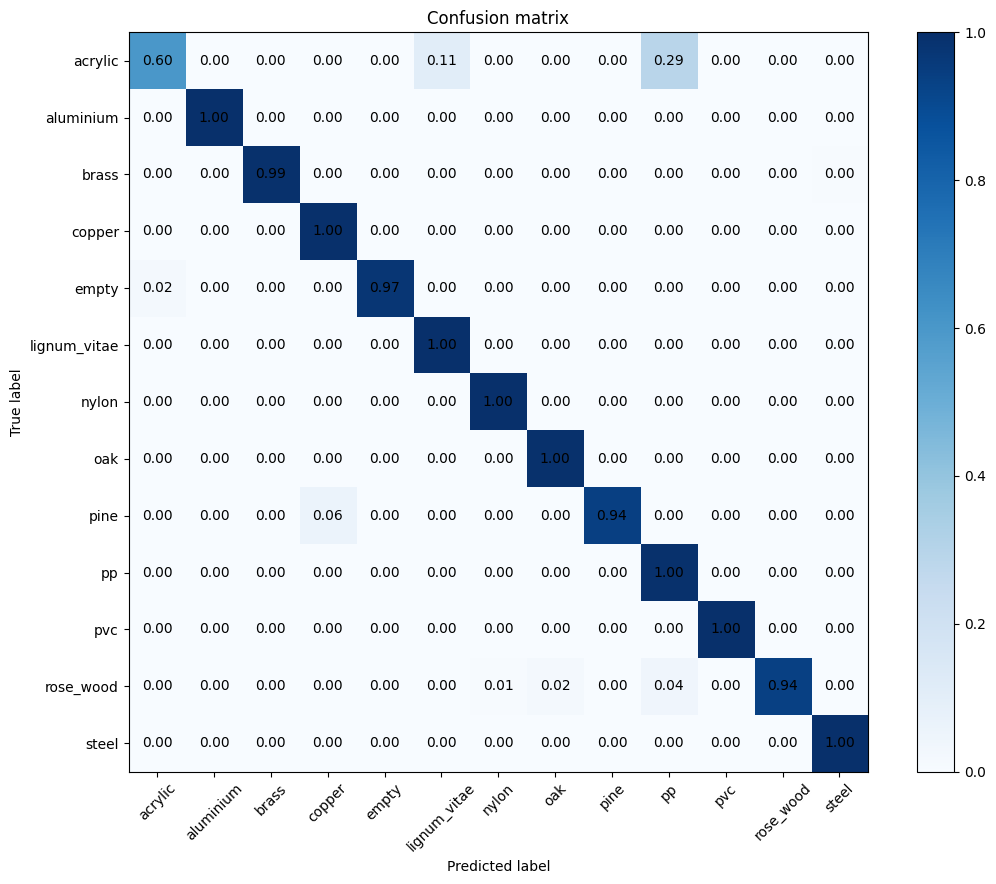

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

#### Amplitude + RSSI
Test using as features amplitude and RSSI


The lowest loss is at the epoch 18


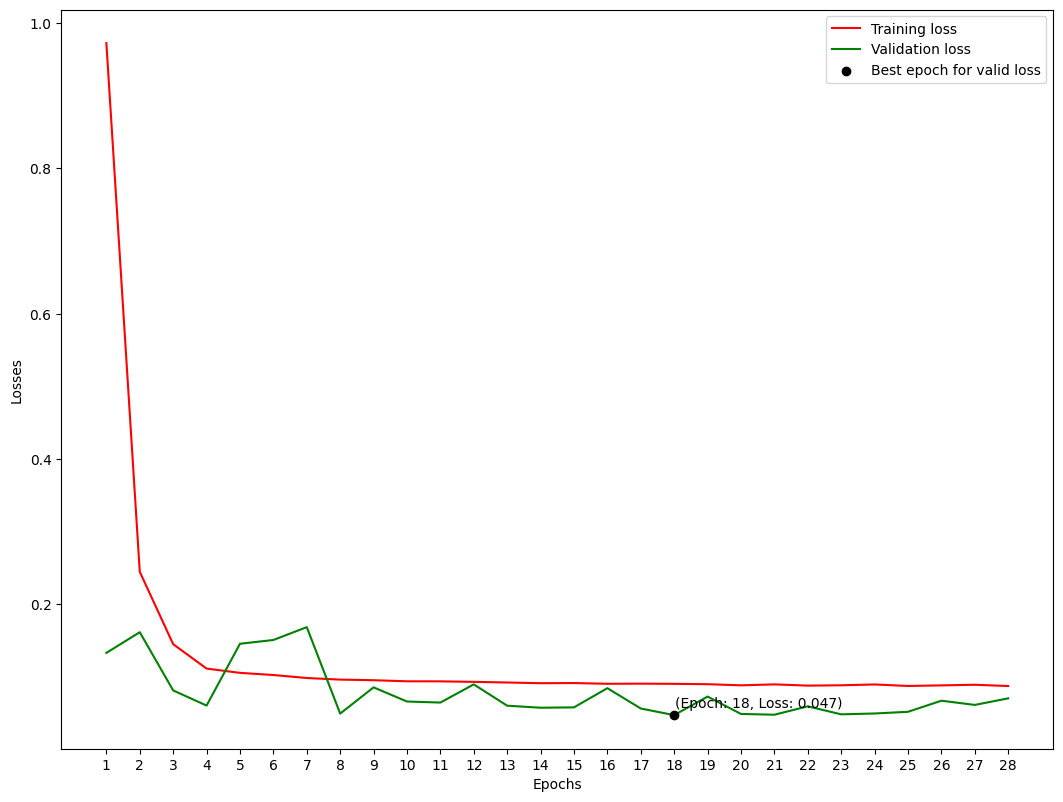

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/330 [00:00<?, ?it/s]

f1: 0.952169967229552
accuracy: 0.9528878983308042
precision: 0.958164828290103
recall: 0.9528878983308042


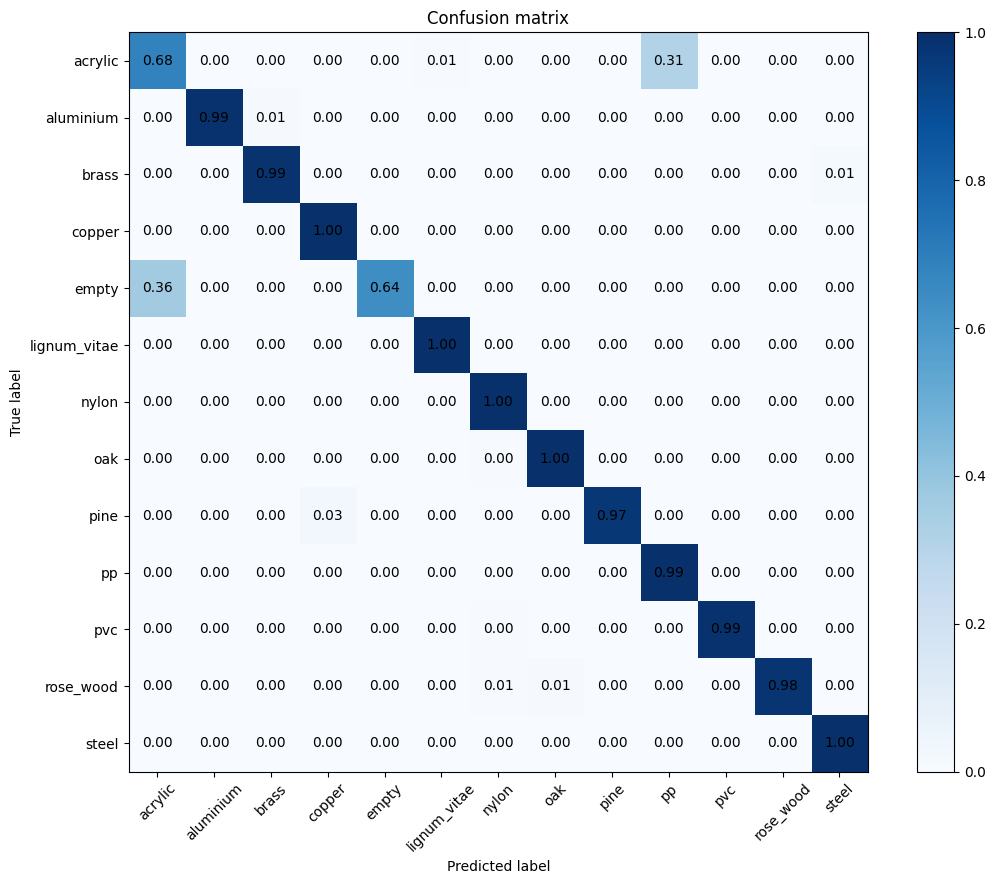

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

#### Amplitude + Phase + RSSI
Test using as features amplitude, phase and RSSI


The lowest loss is at the epoch 20


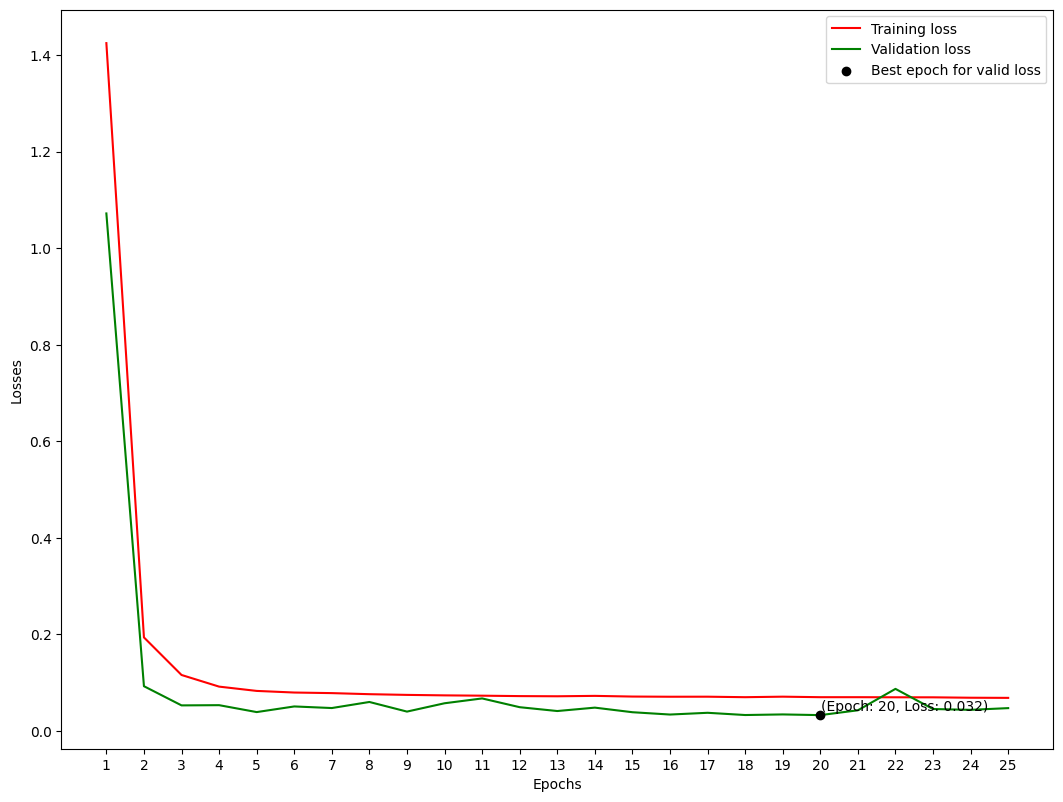

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/330 [00:00<?, ?it/s]

f1: 0.9719329675125121
accuracy: 0.9724724962063733
precision: 0.9768243778896273
recall: 0.9724724962063733


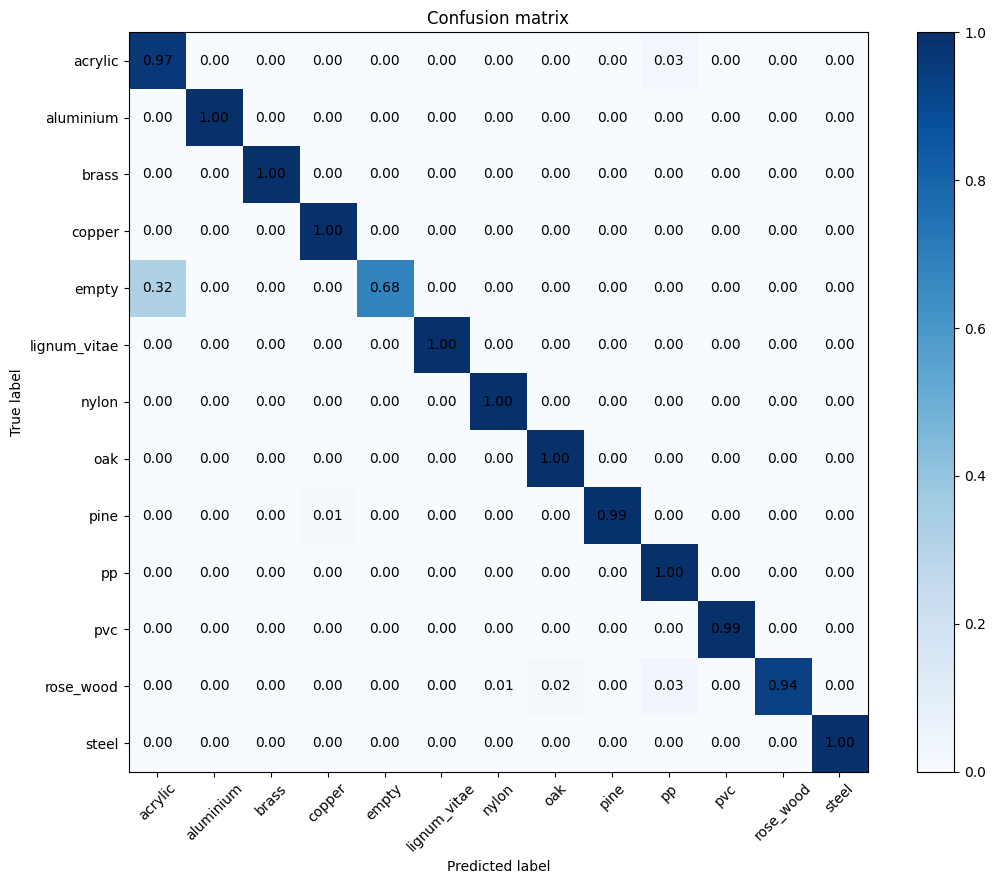

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()

### Conv1d + Conv2d
Test performed with the combination of CNN 1D and CNN 2D. The features used are amplitude, phase and RSSI. Specifically, CNN1D processes the phase, while CNN 2D processes the combination of amplitude, phase and RSSI.


The lowest loss is at the epoch 18


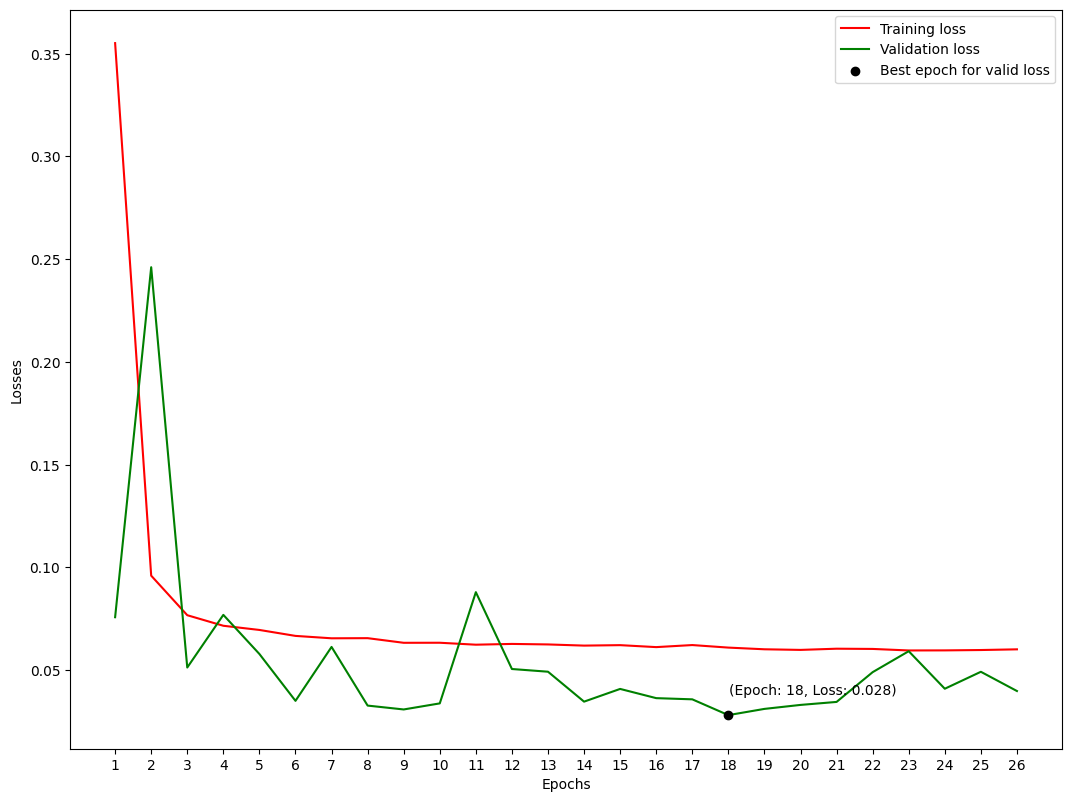

In [ ]:
valid_losses = trainer.valid_losses
train_losses = trainer.train_losses
epoch = len(trainer.valid_losses)
ep = np.arange(1,epoch+1,1)

print()
print("The lowest loss is at the epoch", np.argmin(valid_losses)+1)

# PLOTS
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
# Validation and training curve
plt.plot(ep, train_losses, c = "red", label = "Training loss")
plt.plot(ep, valid_losses, c = "green", label = "Validation loss")
# Best epoch for validation loss
plt.scatter(np.argmin(valid_losses)+1, valid_losses[np.argmin(valid_losses)],
            c = "black", label = "Best epoch for valid loss", zorder=3)
plt.text(np.argmin(valid_losses)+1 + 0.01, valid_losses[np.argmin(valid_losses)] + 0.01,
         '(Epoch: {}, Loss: {})'.format(np.argmin(valid_losses)+1,
                                        np.round(valid_losses[np.argmin(valid_losses)], 3)),
         zorder=4)
# Aesthetics
plt.xticks(ep)
plt.xlabel("Epochs")
plt.ylabel("Losses")
plt.legend()

Test - Batch:   0%|          | 0/330 [00:00<?, ?it/s]

f1: 0.9819840758350036
accuracy: 0.9820751138088012
precision: 0.9827661100787378
recall: 0.9820751138088012


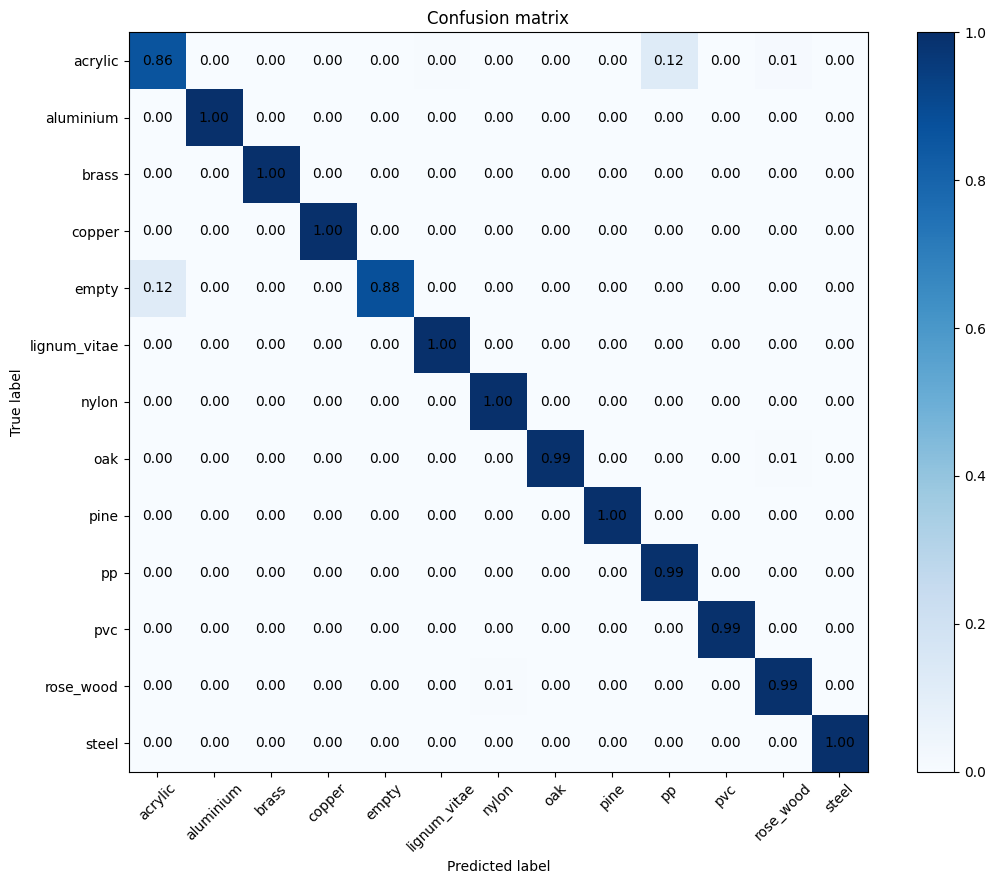

In [ ]:
f1, accuracy, precision, recall, cm = trainer.test(test_data_loader)
# Plot the confusion matrix
plt.figure(figsize=(6.4*2, 4.8*2), constrained_layout=False)
plt.imshow(cm, interpolation='nearest', cmap=plt.cm.Blues)
plt.title("Confusion matrix")
plt.xticks(range(len(LABEL)), LABEL, rotation=45)
plt.yticks(range(len(LABEL)), LABEL)
plt.xlabel("Predicted label")
plt.ylabel("True label")
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        # Format value with two decimal places using f-strings
        text = f"{cm[i, j]:.2f}"
        plt.text(j, i, text, ha="center", va="center", fontsize=10)
plt.colorbar()
plt.show()